# Copper Forecasting — SA-LSTM Paper vs Prior-SA Reoptimized vs LSTM vs RNN (H=1)

**Run All Kaggle notebook**, only next-session forecasting: Copper(t) from inputs through t-1. Four input variants: Paper3 and Legacy14, each WITH and WITHOUT Copper lag. All original metrics, 3 training strategies, 4 ratios, plots, artifact ZIP.

**Important scientific distinctions:** Paper-SA uses published recurrent units (39/111) and learning rate 5e-5, while unspecified Dense(32) remains an implementation assumption. Reoptimized SA uses **fixed values already found in the original notebook** (Paper3 22/91, lr 0.000922; Legacy14 22/83, lr 0.000655) and does **not** search again. These HP were selected with Copper lag; applying to no-Copper condition is a transfer study rather than a fresh SA optimization. Early stopping in FULL_MODE means 100 is maximum epochs, not necessarily completed epochs.

**Input timeline:** For target date t, window consists of t-22 ... t-1. Naive always uses Copper(t-1) as its standalone baseline, even when neural-model inputs exclude Copper. Strategies determine training data; no walk-forward repeated retraining is claimed.


## 1. Environment and configuration

In [2]:
from pathlib import Path
import os, gc, json, time, math, hashlib, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf

# ─── CHẾ ĐỘ THỰC NGHIỆM ─────────────────────────────────────────────────────────
# 'QUICK_MODE': Smoke test logic 5 epochs; không SA search
# 'FULL_MODE': 100 epochs tối đa với EarlyStopping; không SA search
# 'EXACT_PAPER_MODE': Chạy đúng 100 epochs cố định không early stopping, 3 tỷ lệ bài báo (0.9, 0.925, 0.95)
MODE = 'FULL_MODE'
MODE_CFG = {
    'QUICK_MODE':       {'epochs': 5,   'search_epochs': 3,  'sa_evals': 5,   'earlystop': True},
    'FULL_MODE':        {'epochs': 100, 'search_epochs': 12, 'sa_evals': 0, 'earlystop': True},
    'EXACT_PAPER_MODE': {'epochs': 100, 'search_epochs': 25, 'sa_evals': 50,  'earlystop': False}
}
CFG = MODE_CFG[MODE]

# ─── THIẾT LẬP PHƯƠNG PHÁP LUẬN V20 & BÀI BÁO GỐC ───────────────────────────────
LOOKBACK = 22
HORIZON = 1          # Cố định HORIZON=1: Protocol V20 (true forecasting, không look-ahead)
# Bài báo Chen et al. (2023) sử dụng 3 tỷ lệ phân chia: 0.90, 0.925, 0.95
# V20 bổ sung thêm 0.80 để khảo sát tính vững chắc trên cửa sổ dài hạn
RATIOS = (0.90, 0.925, 0.95)  # Paper's three ratios; strategies are all checked at PRIMARY_RATIO
PRIMARY_RATIO = 0.90
BATCH_SIZE = 64      # Chuẩn 64 như Bảng 4 bài báo
SEED = 42
# Full matrix is compute-intensive. No automatic timeout or partial success claim.
JOB_START = time.monotonic()

# ─── TẬP ĐẶC TRƯNG KHẢO SÁT ───────────────────────────────────────────────────
# copper_paper3: Bộ biến theo bài báo Chen et al. (Copper + WTI + Gold + Silver)
# copper_legacy14: Bộ biến mở rộng 5 kim loại (Copper + Aluminium + Tin + Silver + Gold)
FEATURE_SETS = {
    'paper3_with_copper': ['Copper', 'WTI', 'Gold', 'Silver'],
    'paper3_without_copper': ['WTI', 'Gold', 'Silver'],
    'legacy14_with_copper': ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold'],
    'legacy14_without_copper': ['Aluminium', 'Tin', 'Silver', 'Gold'],
}
# Re-optimized configurations were originally selected WITH historical Copper input.
# Applying the same HP without Copper is a transfer/ablation experiment, not a fresh SA optimum.
SA_HP_BY_GROUP = {
    'paper3': {'units_1': 22, 'units_2': 91, 'learning_rate': 0.000922},
    'legacy14': {'units_1': 22, 'units_2': 83, 'learning_rate': 0.000655},
}

SCHEMES = ('expanding', 'rolling_756', 'recency_weighted')

# ─── ĐƯỜNG DẪN VÀ CHECKPOINT ──────────────────────────────────────────────────
DATASET_CANDIDATES = [
    Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('/kaggle/input/dataset-9-commodities-daily/dataset_9_commodities_daily.csv'),
    Path('data/processed/dataset_9_commodities_daily.csv'),
    Path('data/raw/dataset_9_commodities_daily.csv'),
    Path('dataset_9_commodities_daily.csv')
]

OUT = Path('/kaggle/working/copper_sa_lstm_h1_ablation_v21') if Path('/kaggle/working').exists() else Path('copper_sa_lstm_h1_ablation_v21')
OUT.mkdir(parents=True, exist_ok=True)

# Cố định tính ngẫu nhiên
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass

print('═'*75)
print(f'COPPER SA-LSTM BENCHMARK | CHẾ ĐỘ: {MODE}')
print(f'Epochs: {CFG["epochs"]} (Chuẩn bài báo 100) | Batch Size: {BATCH_SIZE} | EarlyStop: {CFG["earlystop"]}')
print(f'Horizon: {HORIZON} | Lookback: {LOOKBACK} | Seed: {SEED}')
print(f'Splits: {[f"{r*100:g}%" for r in RATIOS]}')
print(f'Feature Sets: {list(FEATURE_SETS.keys())}')
print(f'GPU Devices: {tf.config.list_physical_devices("GPU")}')
print(f'Output Directory: {OUT.resolve()}')

print('SA search DISABLED: using fixed, precomputed parameters from the uploaded notebook.')


I0000 00:00:1795013038.136101      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795013052.999108      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


═══════════════════════════════════════════════════════════════════════════
COPPER SA-LSTM BENCHMARK | CHẾ ĐỘ: FULL_MODE
Epochs: 100 (Chuẩn bài báo 100) | Batch Size: 64 | EarlyStop: True
Horizon: 1 | Lookback: 22 | Seed: 42
Splits: ['90%', '92.5%', '95%']
Feature Sets: ['paper3_with_copper', 'paper3_without_copper', 'legacy14_with_copper', 'legacy14_without_copper']
GPU Devices: []
Output Directory: /kaggle/working/copper_sa_lstm_h1_ablation_v21
SA search DISABLED: using fixed, precomputed parameters from the uploaded notebook.


E0000 00:00:1795013055.638442      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Input dataset and quality

In [6]:
TARGET = 'Copper'
REQUIRED_COLS = ['Copper', 'WTI', 'Gold', 'Silver', 'Aluminium', 'Tin']

DATA_PATH = next((p for p in DATASET_CANDIDATES if p.is_file()), None)
if DATA_PATH is None and Path('/kaggle/input').exists():
    matches = list(Path('/kaggle/input').rglob('dataset_9_commodities_daily.csv'))
    if len(matches) == 1: DATA_PATH = matches[0]
if DATA_PATH is None:
    raise FileNotFoundError('Không tìm thấy file dataset_9_commodities_daily.csv. Vui lòng kiểm tra đường dẫn.')

raw = pd.read_csv(DATA_PATH)
if 'Date' not in raw.columns or TARGET not in raw.columns:
    raise KeyError('Tệp CSV phải có cột Date và Copper.')

raw['Date'] = pd.to_datetime(raw['Date'], errors='coerce')
if raw['Date'].isna().any(): raise ValueError('Cột Date có dòng không hợp lệ.')
if raw['Date'].duplicated().any(): raise ValueError('Có ngày bị trùng lặp; cần xử lý nguồn dữ liệu.')

for col in REQUIRED_COLS:
    if col not in raw.columns: raise ValueError(f'Thiếu cột bắt buộc: {col}')
    raw[col] = pd.to_numeric(raw[col], errors='coerce')

raw = raw.sort_values('Date').reset_index(drop=True)
quality = pd.DataFrame({
    'column': raw.columns,
    'missing': raw.isna().sum().values,
    'dtype': raw.dtypes.astype(str).values
})
quality.to_csv(OUT / 'data_quality.csv', index=False)

# Làm sạch dữ liệu trên hợp các biến cần dùng
data = raw.dropna(subset=REQUIRED_COLS).reset_index(drop=True)
assert len(data) > 1000 and data['Date'].is_monotonic_increasing
assert all((data[c] > 0).all() for c in REQUIRED_COLS), 'Giá <= 0: cần kiểm toán dữ liệu trước khi huấn luyện.'

dataset_sha256 = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
(OUT / 'dataset_fingerprint.txt').write_text(dataset_sha256)

print(f'Nạp dữ liệu thành công từ: {DATA_PATH}')
print(f'Tổng số phiên: {len(data):,} phiên | Từ ngày {data.Date.iloc[0].date()} đến {data.Date.iloc[-1].date()}')
print(f'SHA256 Fingerprint: {dataset_sha256[:16]}...')
display(quality[quality['column'].isin(['Date'] + REQUIRED_COLS)])

Nạp dữ liệu thành công từ: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
Tổng số phiên: 2,710 phiên | Từ ngày 2016-01-13 đến 2026-11-13
SHA256 Fingerprint: 9580ede12d474c8f...


,column,missing,dtype
0,Date,0,datetime64[ns]
1,Copper,0,float64
2,Aluminium,0,float64
4,Tin,0,float64
6,Silver,0,float64
7,Gold,0,float64
8,WTI,0,float64


## 3. Time-safe train / validation / test and sliding windows

In [16]:
def make_context(frame, ratio, scheme='expanding', feature_set='paper3_with_copper', val_fraction=0.10):
    n = len(frame)
    split = int(n * ratio)
    val_start = int(split * (1.0 - val_fraction))
    fit_start = 0 if scheme != 'rolling_756' else max(0, val_start - 756)
    cols = FEATURE_SETS[feature_set]
    assert LOOKBACK + 25 < val_start < split < n
    assert val_start - fit_start > LOOKBACK + 10
    # Train-only scaling: no future statistics leak into scaler.
    xsc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][cols])
    ysc = MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x = xsc.transform(frame[cols]).astype('float32')
    y = ysc.transform(frame[[TARGET]]).ravel().astype('float32')
    prev = np.r_[np.nan, y[:-1]]
    def block(start, end, restrict_train=False):
        indices = np.arange(max(start, LOOKBACK), end)
        if restrict_train:
            indices = indices[indices-LOOKBACK >= fit_start]
        X = np.stack([x[t-LOOKBACK:t] for t in indices]).astype('float32')
        return {'idx': indices, 'X': X, 'y': y[indices],
                'prev': prev[indices].astype('float32'),
                'date': frame.Date.iloc[indices].to_numpy()}
    tr = block(fit_start, val_start, True)
    va = block(val_start, split)
    te = block(split, n)
    assert tr['idx'][-1] < va['idx'][0] < te['idx'][0]
    assert xsc.n_samples_seen_ == val_start - fit_start
    assert len(tr['X']) > 0 and tr['X'].shape[1:] == (LOOKBACK, len(cols))
    # Last X timestamp is always t-1. Verify Copper only if included.
    if 'Copper' in cols:
        copper_col = cols.index('Copper')
        copper_raw_in_x = xsc.inverse_transform(x[tr['idx']-1])[:, copper_col]
        copper_true = frame.iloc[tr['idx']-1]['Copper'].to_numpy()
        assert np.allclose(copper_raw_in_x, copper_true, atol=1e-4)
    return {'train': tr, 'val': va, 'test': te, 'xsc': xsc, 'ysc': ysc,
            'features': cols, 'feature_set': feature_set, 'horizon': 1,
            'ratio': float(ratio), 'scheme': scheme,
            'fit_start': fit_start, 'val_start': val_start, 'test_start': split}

for feature_set in FEATURE_SETS:
    ctx = make_context(data, PRIMARY_RATIO, 'expanding', feature_set)
    assert ctx['train']['X'].shape[-1] == len(FEATURE_SETS[feature_set])
    assert np.array_equal(ctx['test']['idx'], make_context(data, PRIMARY_RATIO, 'expanding', 'paper3_with_copper')['test']['idx'])
    print(feature_set, ctx['train']['X'].shape, ctx['val']['X'].shape, ctx['test']['X'].shape)
print('PASS: Horizon=1 and feature ablation integrity checks')


paper3_with_copper (2173, 22, 4) (244, 22, 4) (271, 22, 4)
paper3_without_copper (2173, 22, 3) (244, 22, 3) (271, 22, 3)
legacy14_with_copper (2173, 22, 5) (244, 22, 5) (271, 22, 5)
legacy14_without_copper (2173, 22, 4) (244, 22, 4) (271, 22, 4)
PASS: Horizon=1 and feature ablation integrity checks


## 4. Architectures: Paper-SA LSTM, prior-SA LSTM, baseline LSTM, baseline SimpleRNN

In [17]:
PAPER_SA_LSTM_HP = {'units_1': 39, 'units_2': 111, 'learning_rate': 5e-5}

def build_baseline_lstm(input_shape, hp=None):
    """Mô hình LSTM chuẩn không tối ưu SA (Protocol V20 baseline)."""
    model = tf.keras.Sequential(name='Baseline_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

def build_paper_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM với siêu tham số công bố trong bài báo Chen et al. (2023)."""
    model = tf.keras.Sequential(name='Paper_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(39, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(111, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(5e-5), loss='mse')
    return model

def build_sa_lstm(input_shape, hp=None):
    """Kiến trúc SA-LSTM nhận siêu tham số linh hoạt do SA tìm kiếm (hỗ trợ Paper3, Legacy14, H=1, H=0)."""
    h = hp or PAPER_SA_LSTM_HP
    u1 = int(h.get('units_1', 39))
    u2 = int(h.get('units_2', 111))
    lr = float(h.get('learning_rate', 5e-5))
    
    model = tf.keras.Sequential(name='Reoptimized_SA_LSTM')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.LSTM(u1, return_sequences=True, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.LSTM(u2, activation='tanh', recurrent_activation='sigmoid'))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(32, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='mse')
    return model

# Đặt alias tương thích ngược nếu có đoạn gọi tên riêng
build_sa_lstm_paper3 = build_sa_lstm
build_sa_lstm_legacy14 = build_sa_lstm

print('Đã khởi tạo xong các hàm dựng mô hình LSTM (bao gồm build_sa_lstm).')

def build_baseline_rnn(input_shape, hp=None):
    """SimpleRNN baseline with two recurrent layers and comparable head."""
    model = tf.keras.Sequential(name='Baseline_RNN')
    model.add(tf.keras.layers.Input(shape=input_shape))
    model.add(tf.keras.layers.SimpleRNN(64, return_sequences=True))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.SimpleRNN(32))
    model.add(tf.keras.layers.Dropout(0.20))
    model.add(tf.keras.layers.Dense(16, activation='relu'))
    model.add(tf.keras.layers.Dense(1, activation='linear'))
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model


Đã khởi tạo xong các hàm dựng mô hình LSTM (bao gồm build_sa_lstm).


## 5. Training and metrics

In [18]:
def reset_keras(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(int(seed))

def sample_weights(length, scheme, half_life=252):
    if scheme != 'recency_weighted': return None
    ages = np.arange(length - 1, -1, -1, dtype='float64')
    w = np.exp(-np.log(2) * ages / half_life)
    return (w / w.mean()).astype('float32')

def evaluate_predictions(ctx, model_name, p_val, p_test, seed=SEED, extras=None):
    ysc = ctx['ysc']; va = ctx['val']; te = ctx['test']
    def original(z): return ysc.inverse_transform(np.asarray(z).reshape(-1, 1)).ravel()
    
    # 1. Dịch ngược về giá gốc (USD)
    y_true = original(te['y'])
    pred = original(p_test)
    base = original(te['prev'])
    
    delta_pred = pred - base
    delta_true = y_true - base
    
    # 2. Tính các độ đo trên giá gốc (RAW - USD) khớp 100% với V20
    mae = float(mean_absolute_error(y_true, pred))
    rmse = float(np.sqrt(mean_squared_error(y_true, pred)))
    mse = float(mean_squared_error(y_true, pred))  # DỊCH NGƯỢC LẠI GIÁ GỐC (USD^2) - KHỚP V20
    base_mae = float(mean_absolute_error(y_true, base))
    improvement = float(100.0 * (base_mae - mae) / base_mae) if base_mae > 0 else 0.0
    
    # 3. Tính các độ đo trên thang đo chuẩn hóa (SCALED [0, 1])
    val_mse_scaled = float(mean_squared_error(va['y'], p_val))
    mse_scaled = float(mean_squared_error(te['y'], p_test)) if p_test is not None else np.nan
    
    # 4. Tính Directional Accuracy và các thống kê kiểm toán phần dư
    dir_acc = float(100.0 * np.mean(np.sign(delta_pred) == np.sign(delta_true))) if model_name != 'naive' else np.nan
    delta_pred_std = float(np.std(delta_pred))
    delta_true_std = float(np.std(delta_true))
    delta_pred_mean_abs = float(np.mean(np.abs(delta_pred)))
    pred_delta_corr = float(np.corrcoef(delta_pred, delta_true)[0, 1]) if delta_pred_std > 1e-12 else np.nan
    
    row = {
        'model': model_name,
        'feature_set': ctx['feature_set'],
        'copper_history': 'Copper' in ctx['features'],
        'feature_group': ctx['feature_set'].split('_')[0],
        'scheme': ctx['scheme'],
        'ratio': ctx['ratio'],
        'seed': int(seed),
        'n_test': len(y_true),
        'mae': mae,
        'rmse': rmse,
        'mse': mse,                        # GIÁ GỐC DỊCH NGƯỢC (USD^2) - KHỚP V20
        'mse_scaled': mse_scaled,          # SCALED TRÊN TẬP TEST [0, 1]
        'mae_naive': base_mae,
        'mae_improvement_pct': improvement,
        'val_mse_scaled': val_mse_scaled,  # SCALED TRÊN TẬP VALIDATION [0, 1] - KHỚP V20
        'directional_accuracy_pct': dir_acc,
        'delta_pred_std_raw': delta_pred_std,
        'delta_true_std_raw': delta_true_std,
        'delta_pred_mean_abs_raw': delta_pred_mean_abs,
        'pred_delta_corr': pred_delta_corr,
        'test_start': str(pd.Timestamp(te['date'][0]).date()),
        'fit_start': str(data.Date.iloc[ctx['fit_start']].date())
    }
    if extras: row.update(extras)
    
    predictions = pd.DataFrame({
        'Date': te['date'],
        'ratio': ctx['ratio'],
        'scheme': ctx['scheme'],
        'feature_set': ctx['feature_set'],
        'copper_history': 'Copper' in ctx['features'],
        'feature_group': ctx['feature_set'].split('_')[0],
        'model': model_name,
        'seed': int(seed),
        'actual': y_true,
        'pred': pred,
        'naive': base,
        'pred_delta': delta_pred,
        'actual_delta': delta_true
    })
    return row, predictions

def fit_predict_model(builder, ctx, hp=None, seed=SEED, epochs=None, patience=None, is_search=False, skip_test=False):
    reset_keras(seed)
    tr, va, te = ctx['train'], ctx['val'], ctx['test']
    model = builder(tr['X'].shape[1:], hp)
    
    cb = []
    if CFG['earlystop']:
        pat = patience if patience is not None else (4 if is_search else 9)
        cb.append(tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=pat, restore_best_weights=True))
        
    ep = epochs if epochs is not None else (CFG['search_epochs'] if is_search else CFG['epochs'])
    weights = sample_weights(len(tr['idx']), ctx['scheme'])
    
    start_t = time.perf_counter()
    hist = model.fit(
        tr['X'], tr['y'],
        validation_data=(va['X'], va['y']),
        epochs=ep,
        batch_size=BATCH_SIZE,
        sample_weight=weights,
        callbacks=cb,
        shuffle=False,
        verbose=0
    )
    fit_sec = time.perf_counter() - start_t
    
    pv = model.predict(va['X'], verbose=0).ravel()
    pt = model.predict(te['X'], verbose=0).ravel() if not skip_test else None
    val_mse = float(mean_squared_error(va['y'], pv))
    epochs_run = len(hist.history['loss'])
    
    del model
    reset_keras(seed)
    return {'val_pred': pv, 'test_pred': pt, 'val_mse': val_mse, 'seconds': fit_sec, 'epochs_run': epochs_run}

## 6. Fixed hyperparameters — no SA search

In [19]:
# Precomputed SA hyperparameters from the supplied notebook; DO NOT run SA again.
PAPER_SA_LSTM_HP = {'units_1': 39, 'units_2': 111, 'learning_rate': 5e-5}
sa_best_cache = {
    'paper3': dict(SA_HP_BY_GROUP['paper3']),
    'legacy14': dict(SA_HP_BY_GROUP['legacy14']),
}
(OUT / 'fixed_sa_hyperparameters.json').write_text(json.dumps({'paper':PAPER_SA_LSTM_HP,'reoptimized':sa_best_cache}, indent=2))
display(pd.DataFrame([{'source':'Chen et al. (2023) paper configuration', **PAPER_SA_LSTM_HP},
                      {'source':'Prior SA search, Paper3 with Copper', **sa_best_cache['paper3']},
                      {'source':'Prior SA search, Legacy14 with Copper', **sa_best_cache['legacy14']}]))
print('No SA search will be run. Only final model training.')


,source,units_1,units_2,learning_rate
0,Chen et al. (2023) paper configuration,39,111,0.000050
1,"Prior SA search, Paper3 with Copper",22,91,0.000922
2,"Prior SA search, Legacy14 with Copper",22,83,0.000655


No SA search will be run. Only final model training.


## 7. Full factorial benchmark (H=1 only)

In [20]:
RESULT_CSV = OUT / 'results_h1_ablation.csv'
PRED_CSV = OUT / 'predictions_h1_ablation.csv'
# 90/10 runs all 3 strategies; 92.5/7.5 and 95/5 run Expanding only.
# Default: recompute cleanly on every Run All, to avoid mixing older results/settings.
# Optional set True to resume interrupted runs with identical configuration.
RESUME = False
RUN_FINGERPRINT = hashlib.sha256(json.dumps({'mode':MODE,'ratios':RATIOS,'schemes':SCHEMES,
    'features':FEATURE_SETS,'sa':sa_best_cache,'seed':SEED,'lookback':LOOKBACK,'horizon':HORIZON}, sort_keys=True).encode()).hexdigest()[:16]
if not RESUME:
    for f in [RESULT_CSV, PRED_CSV]:
        if f.exists(): f.unlink()
RESULT_ROWS = pd.read_csv(RESULT_CSV).to_dict('records') if RESULT_CSV.exists() else []

def has_job_completed(model_name, feature_set, scheme, ratio, seed=SEED):
    return any(str(r.get('run_fingerprint')) == RUN_FINGERPRINT and
               str(r.get('model')) == str(model_name) and
               str(r.get('feature_set')) == str(feature_set) and
               str(r.get('scheme')) == str(scheme) and
               abs(float(r.get('ratio', -1)) - float(ratio)) < 1e-6 and
               int(r.get('seed', -1)) == int(seed) for r in RESULT_ROWS)

def record_evaluation(row, pred_df):
    row['run_fingerprint'] = RUN_FINGERPRINT
    pred_df['run_fingerprint'] = RUN_FINGERPRINT
    RESULT_ROWS.append(row)
    pd.DataFrame(RESULT_ROWS).to_csv(RESULT_CSV, index=False)
    pred_df.to_csv(PRED_CSV, mode='a', header=not PRED_CSV.exists(), index=False)

MODEL_CONFIGS = [
    ('naive', None),
    ('baseline_lstm', build_baseline_lstm),
    ('baseline_rnn', build_baseline_rnn),
    ('paper_sa_lstm', build_paper_sa_lstm),
    ('reopt_sa_lstm', build_sa_lstm),
]
evaluation_jobs = [(feature_set, scheme, ratio, model_name, builder)
                   for ratio in RATIOS for scheme in (SCHEMES if ratio == PRIMARY_RATIO else ('expanding',))
                   for feature_set in FEATURE_SETS
                   for model_name, builder in MODEL_CONFIGS]
print('Planned jobs:',len(evaluation_jobs),'(including Naive; NO SA search).')
for i, (feature_set, scheme, ratio, model_name, builder) in enumerate(evaluation_jobs, 1):
    if has_job_completed(model_name, feature_set, scheme, ratio):
        continue
    ctx = make_context(data, ratio, scheme, feature_set)
    hp = (PAPER_SA_LSTM_HP if model_name == 'paper_sa_lstm' else
          sa_best_cache[feature_set.split('_')[0]] if model_name == 'reopt_sa_lstm' else None)
    if model_name == 'naive':
        pv, pt = ctx['val']['prev'], ctx['test']['prev']
        extras = {'epochs_run': 0, 'fit_seconds': 0.0, 'hp_config': 'naive'}
    else:
        res = fit_predict_model(builder, ctx, hp=hp)
        pv, pt = res['val_pred'], res['test_pred']
        extras = {'epochs_run': res['epochs_run'], 'fit_seconds': res['seconds'],
                  'hp_config': json.dumps(hp) if hp else '{}'}
    row, pred = evaluate_predictions(ctx, model_name, pv, pt, extras=extras)
    record_evaluation(row, pred)
    print(f'[{i:03}/{len(evaluation_jobs)}] {feature_set:24} {scheme:16} {ratio:.3f} '
          f'{model_name:15} MAE={row["mae"]:.5f} Skill={row["mae_improvement_pct"]:+.2f}% '
          f'({row["fit_seconds"]:.1f}s)', flush=True)
print('Completed',len(RESULT_ROWS),'jobs. Files:', RESULT_CSV, PRED_CSV)


Planned jobs: 100 (including Naive; NO SA search).
[001/100] paper3_with_copper       expanding        0.900 naive           MAE=0.07708 Skill=+0.00% (0.0s)


KeyboardInterrupt: 

## 8. Result tables and feature ablation

In [8]:
df_res = pd.read_csv(RESULT_CSV)
assert not df_res.empty and df_res['run_fingerprint'].eq(RUN_FINGERPRINT).all()
show_cols = ['feature_set','scheme','ratio','model','mae','rmse','mse','mse_scaled','val_mse_scaled',
             'mae_improvement_pct','directional_accuracy_pct','delta_pred_std_raw','epochs_run','fit_seconds']
main = df_res[np.isclose(df_res['ratio'], PRIMARY_RATIO) & df_res['scheme'].eq('expanding')]
print('Main comparison, 90/10 expanding (all 4 feature variants):')
display(main[show_cols].sort_values(['feature_set','mae']))
main[show_cols].to_csv(OUT/'main_comparison_90_expanding.csv',index=False)
# Within each feature group, compare the effect of Copper(t-1) for the same model.
ablation = main.pivot_table(index=['feature_group','model'],columns='copper_history',values=['mae','rmse'])
ablation.to_csv(OUT/'copper_lag_ablation.csv')
print('Copper(t-1) ablation (False = without Copper history, True = with):')
display(ablation)
print('MAE by train ratio, Expanding:')
ratio_table = df_res[df_res.scheme.eq('expanding')].pivot_table(
    index=['feature_set','model'], columns='ratio',values='mae')
ratio_table.to_csv(OUT/'ratio_summary.csv')
display(ratio_table)
print('MAE by training strategy, at 90/10:')
strategy_table = df_res[np.isclose(df_res.ratio,PRIMARY_RATIO)].pivot_table(
    index=['feature_set','model'],columns='scheme',values='mae')
strategy_table.to_csv(OUT/'strategy_summary.csv')
display(strategy_table)


Main comparison, 90/10 expanding (all 4 feature variants):


,feature_set,scheme,ratio,model,mae,rmse,mse,mse_scaled,val_mse_scaled,mae_improvement_pct,directional_accuracy_pct,delta_pred_std_raw,epochs_run,fit_seconds
10,legacy14_with_copper,expanding,0.9,naive,0.077077,0.101033,0.010208,0.001021,0.001392,0.000000,NaN,0.000000,0,0.000000
11,legacy14_with_copper,expanding,0.9,baseline_lstm,0.247409,0.304619,0.092793,0.009278,0.005395,-220.990525,52.767528,0.265054,49,48.219855
13,legacy14_with_copper,expanding,0.9,paper_sa_lstm,0.470929,0.527551,0.278310,0.027827,0.011800,-510.987637,48.708487,0.335999,13,20.657487
14,legacy14_with_copper,expanding,0.9,reopt_sa_lstm,0.510467,0.591630,0.350026,0.034998,0.007384,-562.283913,48.708487,0.311744,18,22.572558
12,legacy14_with_copper,expanding,0.9,baseline_rnn,0.831186,0.886049,0.785082,0.078497,0.006212,-978.387401,46.494465,0.306410,62,32.555921
15,legacy14_without_copper,expanding,0.9,naive,0.077077,0.101033,0.010208,0.001021,0.001392,0.000000,NaN,0.000000,0,0.000000
18,legacy14_without_copper,expanding,0.9,paper_sa_lstm,0.464991,0.566237,0.320624,0.032058,0.011370,-503.282822,48.708487,0.409140,13,22.895651
19,legacy14_without_copper,expanding,0.9,reopt_sa_lstm,0.466595,0.580907,0.337453,0.033741,0.012677,-505.364859,47.601476,0.384937,21,26.509780
16,legacy14_without_copper,expanding,0.9,baseline_lstm,0.854128,0.951383,0.905129,0.090500,0.012584,-1008.152323,46.494465,0.421779,14,16.149185
17,legacy14_without_copper,expanding,0.9,baseline_rnn,0.962108,1.047815,1.097916,0.109776,0.011531,-1148.247207,46.494465,0.417401,17,11.289106


Copper(t-1) ablation (False = without Copper history, True = with):


mae                rmse          
copper_history                  False     True      False     True 
feature_group model                                                
legacy14      baseline_lstm  0.854128  0.247409  0.951383  0.304619
              baseline_rnn   0.962108  0.831186  1.047815  0.886049
              naive          0.077077  0.077077  0.101033  0.101033
              paper_sa_lstm  0.464991  0.470929  0.566237  0.527551
              reopt_sa_lstm  0.466595  0.510467  0.580907  0.591630
paper3        baseline_lstm  1.145988  1.163964  1.239686  1.244205
              baseline_rnn   1.001232  1.385730  1.100559  1.451387
              naive          0.077077  0.077077  0.101033  0.101033
              paper_sa_lstm  0.540720  0.978075  0.632916  1.031897
              reopt_sa_lstm  0.595605  0.877420  0.726573  0.943486

MAE by train ratio, Expanding:


ratio                                     0.900     0.925     0.950
feature_set             model                                      
legacy14_with_copper    baseline_lstm  0.247409  0.292571  0.662176
                        baseline_rnn   0.831186  0.724220  0.902960
                        naive          0.077077  0.075116  0.072799
                        paper_sa_lstm  0.470929  0.541731  0.600953
                        reopt_sa_lstm  0.510467  0.352332  0.541005
legacy14_without_copper baseline_lstm  0.854128  1.187447  1.227023
                        baseline_rnn   0.962108  1.205144  1.171721
                        naive          0.077077  0.075116  0.072799
                        paper_sa_lstm  0.464991  0.431292  0.305362
                        reopt_sa_lstm  0.466595  0.598894  0.516180
paper3_with_copper      baseline_lstm  1.163964  0.402367  0.452409
                        baseline_rnn   1.385730  1.222722  1.019429
                        naive          0.077077  0.075116  0.072799
                        paper_sa_lstm  0.978075  1.113254  0.934395
                        reopt_sa_lstm  0.877420  1.210489  0.938438
paper3_without_copper   baseline_lstm  1.145988  1.463087  1.539318
                        baseline_rnn   1.001232  1.298258  1.043665
                        naive          0.077077  0.075116  0.072799
                        paper_sa_lstm  0.540720  0.495687  0.641287
                        reopt_sa_lstm  0.595605  0.685938  0.846143

MAE by training strategy, at 90/10:


scheme                                 expanding  recency_weighted  \
feature_set             model                                        
legacy14_with_copper    baseline_lstm   0.247409          0.659060   
                        baseline_rnn    0.831186          1.045665   
                        naive           0.077077          0.077077   
                        paper_sa_lstm   0.470929          0.705350   
                        reopt_sa_lstm   0.510467          0.735621   
legacy14_without_copper baseline_lstm   0.854128          0.790417   
                        baseline_rnn    0.962108          0.608387   
                        naive           0.077077          0.077077   
                        paper_sa_lstm   0.464991          0.524705   
                        reopt_sa_lstm   0.466595          0.460227   
paper3_with_copper      baseline_lstm   1.163964          0.564049   
                        baseline_rnn    1.385730          0.973459   
                        naive           0.077077          0.077077   
                        paper_sa_lstm   0.978075          0.917524   
                        reopt_sa_lstm   0.877420          0.511784   
paper3_without_copper   baseline_lstm   1.145988          0.686208   
                        baseline_rnn    1.001232          1.568182   
                        naive           0.077077          0.077077   
                        paper_sa_lstm   0.540720          0.585950   
                        reopt_sa_lstm   0.595605          0.482221   

scheme                                 rolling_756  
feature_set             model                       
legacy14_with_copper    baseline_lstm     0.958466  
                        baseline_rnn      1.115149  
                        naive             0.077077  
                        paper_sa_lstm     0.773310  
                        reopt_sa_lstm     0.977821  
legacy14_without_copper baseline_lstm     0.909432  
                        baseline_rnn      1.128623  
                        naive             0.077077  
                        paper_sa_lstm     0.869224  
                        reopt_sa_lstm     0.624100  
paper3_with_copper      baseline_lstm     0.918796  
                        baseline_rnn      1.316286  
                        naive             0.077077  
                        paper_sa_lstm     0.897077  
                        reopt_sa_lstm     0.974593  
paper3_without_copper   baseline_lstm     1.062130  
                        baseline_rnn      1.321809  
                        naive             0.077077  
                        paper_sa_lstm     0.604594  
                        reopt_sa_lstm     0.644180

## 9. Charts

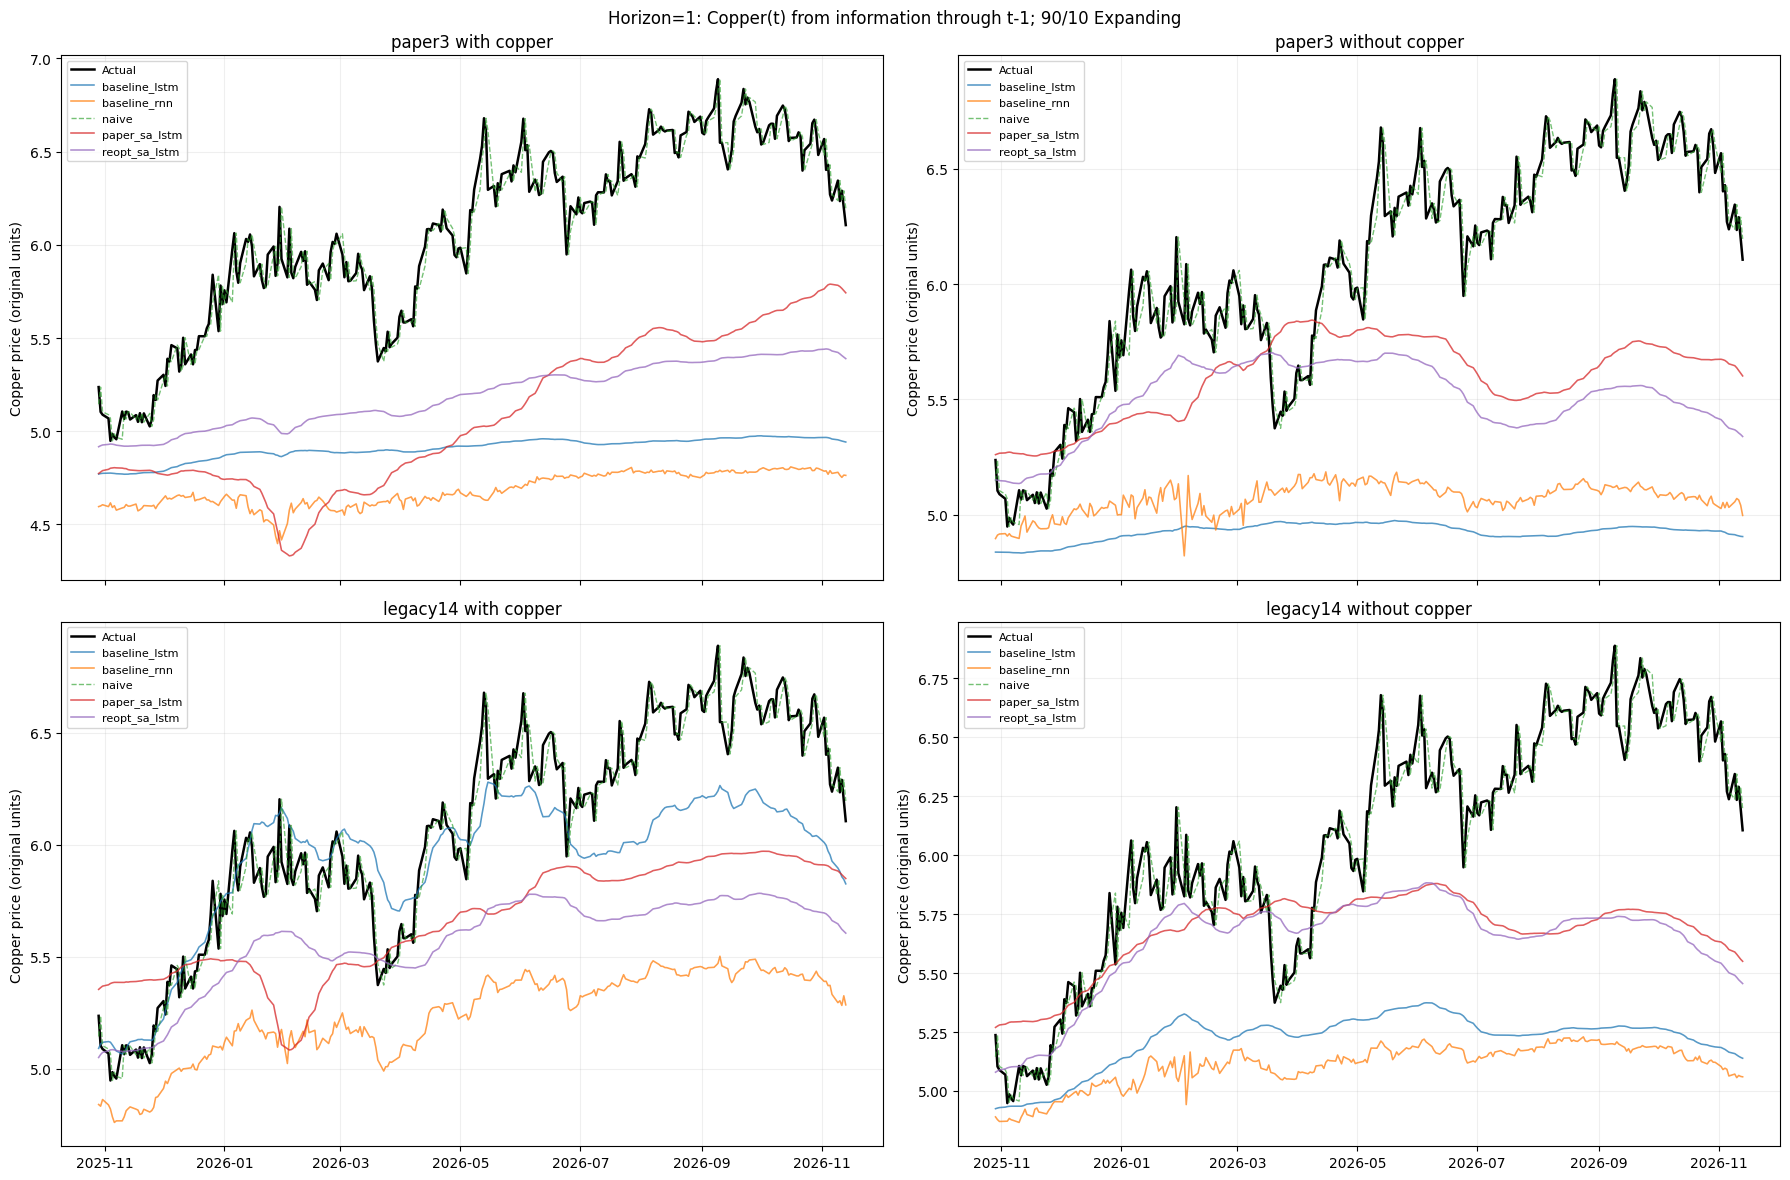

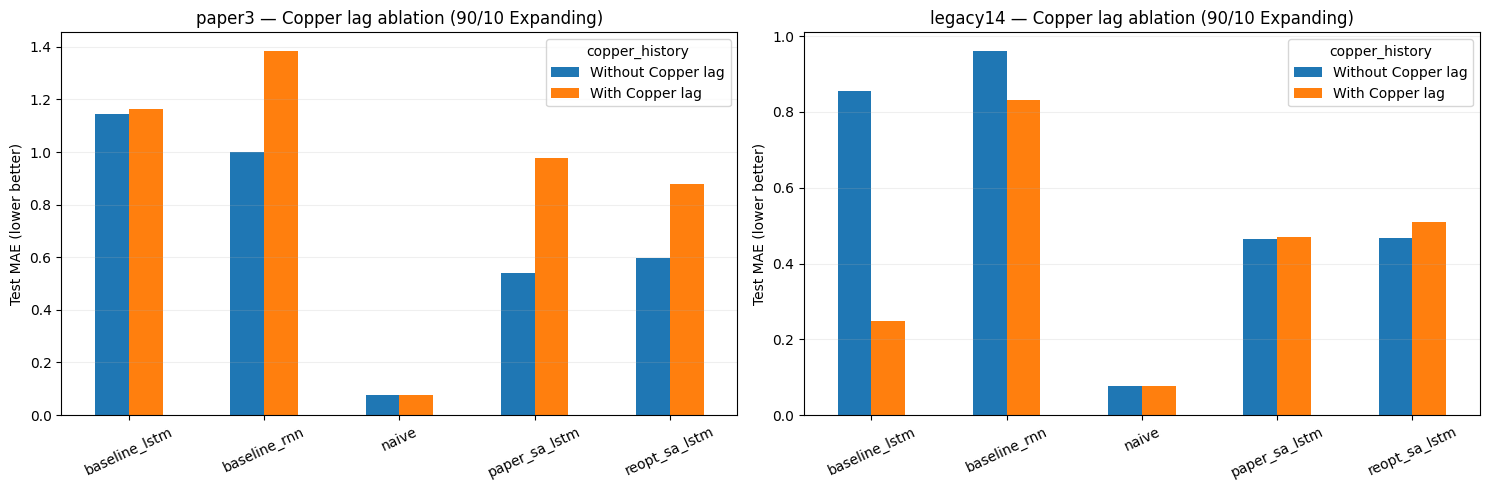

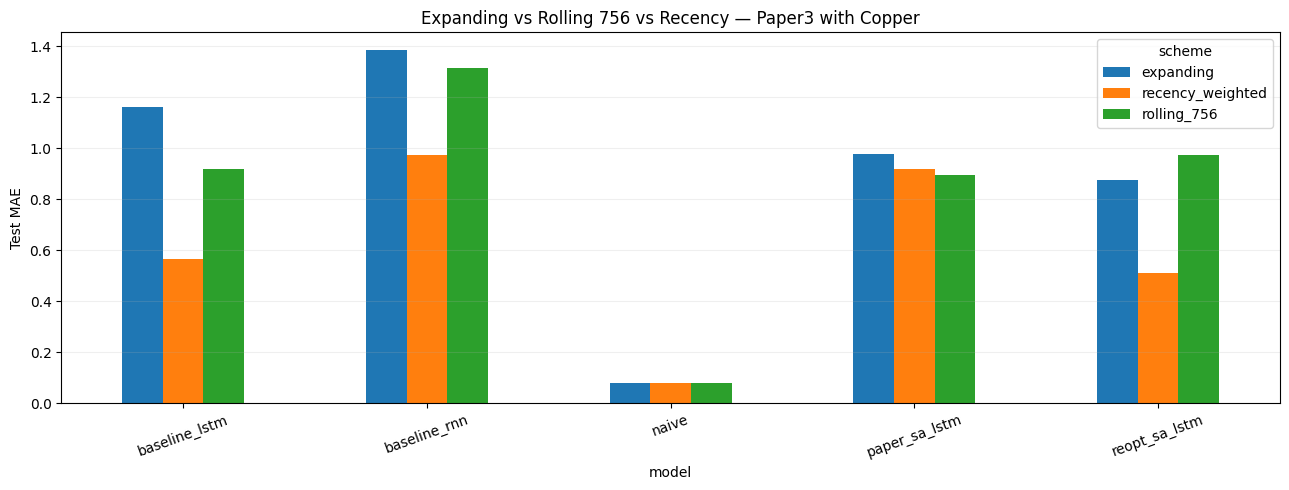

In [9]:
preds = pd.read_csv(PRED_CSV,parse_dates=['Date'])
# Actual vs predicted by features, same 90/10 expanding evaluation.
fig, axes = plt.subplots(2,2,figsize=(18,12),sharex=True)
for ax, feat in zip(axes.ravel(),FEATURE_SETS):
    sub = preds[(preds.feature_set == feat)&np.isclose(preds.ratio,PRIMARY_RATIO)&
                (preds.scheme=='expanding')].sort_values('Date')
    actual = sub.drop_duplicates('Date')
    ax.plot(actual.Date, actual.actual,color='black',lw=1.8,label='Actual')
    for name, g in sub.groupby('model'):
        if name=='naive':
            ax.plot(g.Date,g.pred,lw=1,alpha=.65,ls='--',label=name)
        else:
            ax.plot(g.Date,g.pred,lw=1.15,alpha=.75,label=name)
    ax.set_title(feat.replace('_',' '));ax.set_ylabel('Copper price (original units)')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
plt.suptitle('Horizon=1: Copper(t) from information through t-1; 90/10 Expanding')
plt.tight_layout();plt.savefig(OUT/'actual_vs_predicted_4_variants.png',dpi=150);plt.show()
# Groupwise MAE: with and without Copper lag for every model
fig, axes = plt.subplots(1,2,figsize=(15,5),sharey=False)
for ax, group in zip(axes,['paper3','legacy14']):
    chunk=main[main.feature_group==group].copy()
    piv=chunk.pivot(index='model',columns='copper_history',values='mae').sort_index()
    piv.rename(columns={False:'Without Copper lag',True:'With Copper lag'}).plot(kind='bar',ax=ax)
    ax.set_title(group+' — Copper lag ablation (90/10 Expanding)')
    ax.set_xlabel('');ax.set_ylabel('Test MAE (lower better)');ax.tick_params(axis='x',rotation=25)
    ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'feature_ablation_mae.png',dpi=150);plt.show()
# Strategies bar chart of MAE for a representative feature variant
fig, ax = plt.subplots(figsize=(13,5))
df_res[(df_res.feature_set=='paper3_with_copper')&np.isclose(df_res.ratio,PRIMARY_RATIO)].pivot(
    index='model',columns='scheme',values='mae').plot.bar(ax=ax)
ax.set_ylabel('Test MAE');ax.set_title('Expanding vs Rolling 756 vs Recency — Paper3 with Copper')
ax.tick_params(axis='x',rotation=20);ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'strategies_mae.png',dpi=150);plt.show()


## 10. Results ZIP

In [10]:
runtime_mins=(time.monotonic()-JOB_START)/60
summary_lines=[
'# Copper Forecasting SA-LSTM Comparison — Horizon 1 Only',
'Generated: '+time.strftime('%Y-%m-%d %H:%M:%S'),
'MODE: '+MODE+' | HORIZON: 1 | LOOKBACK: '+str(LOOKBACK),
'Feature variants: '+', '.join(FEATURE_SETS),
'Models: Naive, baseline LSTM, baseline RNN, Paper SA-LSTM, Prior-SA Reoptimized LSTM',
'Strategies: '+', '.join(SCHEMES),
'Fixed HP paper: '+str(PAPER_SA_LSTM_HP),
'Fixed HP prior SA (searched WITH Copper): '+str(sa_best_cache),
'Important: Without-Copper runs TRANSFER existing SA HP, and do NOT re-optimize SA.',
'Important: Paper configuration is partially reconstructed (Dense(32) is an implementation assumption).',
'Important: Values are HOLDOUT comparisons, NOT walk-forward retraining.',
'Samples/rows: '+str(len(df_res)),'Runtime minutes: %.1f'%runtime_mins,
]
(OUT/'run_summary.md').write_text('\n'.join(summary_lines),encoding='utf-8')
zip_path=OUT.parent/(OUT.name+'_results.zip')
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file(): z.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
print('Results ZIP:',zip_path, 'MB:',round(zip_path.stat().st_size/1e6,2))


Results ZIP: /kaggle/working/copper_sa_lstm_h1_ablation_v21_results.zip MB: 1.41


/tmp/ipykernel_50/3988138200.py:73: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Training strategy", fontsize=9)
/tmp/ipykernel_50/3988138200.py:73: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(title="Training strategy", fontsize=9)


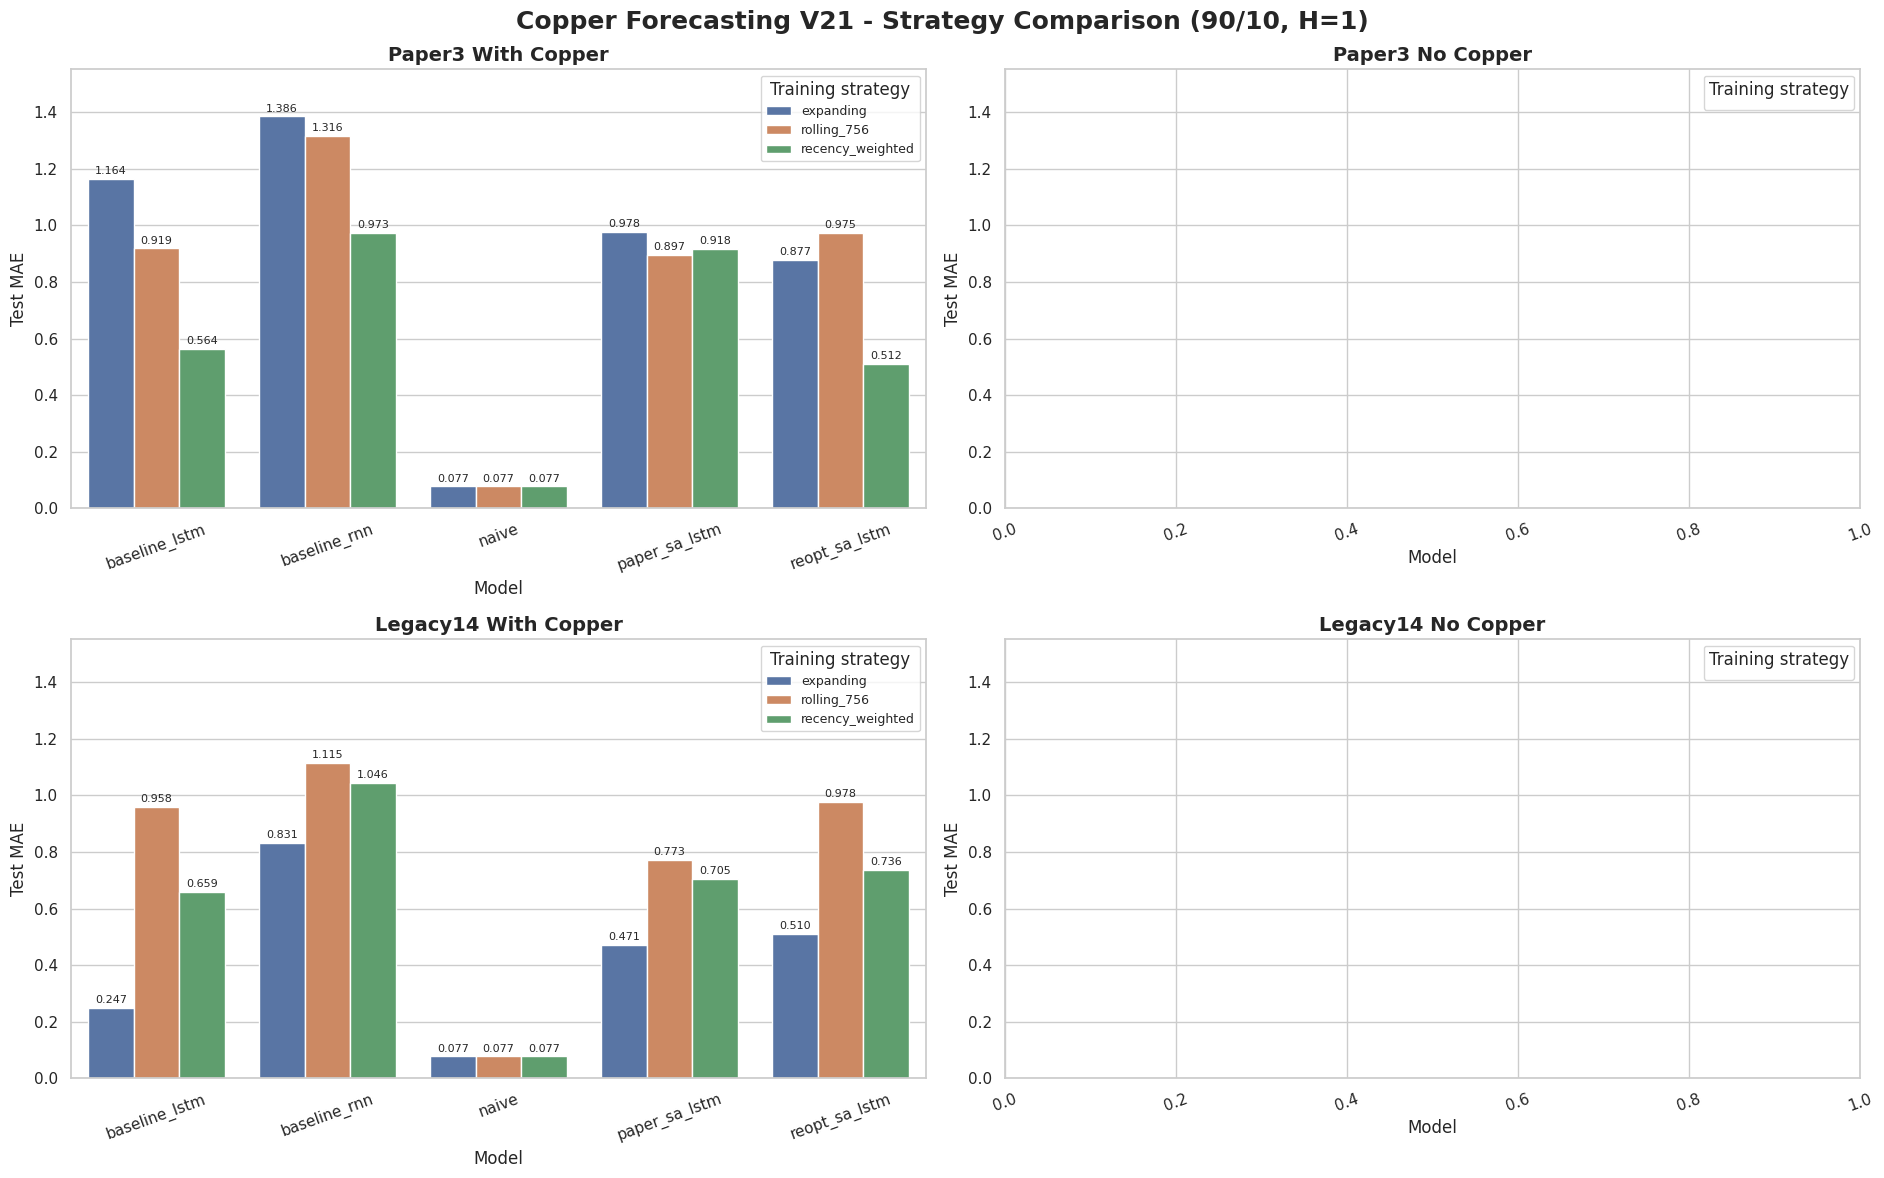

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Đọc kết quả V21
csv_path = Path("copper_sa_lstm_h1_ablation_v21/results_h1_ablation.csv")

# Nếu notebook đã có DataFrame kết quả thì dùng trực tiếp
if "results_df" in globals():
    df = results_df.copy()
elif csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(
        "Không tìm thấy results_df hoặc results_h1_ablation.csv"
    )

# Chỉ lấy split 90/10
df = df[df["ratio"].round(3) == 0.9].copy()

feature_sets = [
    "paper3_with_copper",
    "paper3_no_copper",
    "legacy14_with_copper",
    "legacy14_no_copper"
]

schemes = ["expanding", "rolling_756", "recency_weighted"]

model_order = [
    "baseline_lstm",
    "baseline_rnn",
    "naive",
    "paper_sa_lstm",
    "reopt_sa_lstm"
]

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(19, 12))

for ax, feature in zip(axes.flat, feature_sets):

    subset = df[
        (df["feature_set"] == feature) &
        (df["scheme"].isin(schemes))
    ]

    sns.barplot(
        data=subset,
        x="model",
        y="mae",
        hue="scheme",
        order=model_order,
        hue_order=schemes,
        errorbar=None,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=14,
        fontweight="bold"
    )
    ax.set_xlabel("Model")
    ax.set_ylabel("Test MAE")
    ax.tick_params(axis="x", rotation=20)

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)

    ax.legend(title="Training strategy", fontsize=9)

# Chung thang đo để so sánh công bằng
ymax = df[
    df["feature_set"].isin(feature_sets) &
    df["scheme"].isin(schemes)
]["mae"].max() * 1.12

for ax in axes.flat:
    ax.set_ylim(0, ymax)

fig.suptitle(
    "Copper Forecasting V21 - Strategy Comparison (90/10, H=1)",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "strategy_comparison_all_4_variants.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [12]:
from zipfile import ZipFile, ZIP_DEFLATED

zip_path = "copper_sa_lstm_h1_ablation_v21_results.zip"
image_path = "strategy_comparison_all_4_variants.png"

with ZipFile(zip_path, "a", compression=ZIP_DEFLATED) as z:
    z.write(image_path, arcname="plots/" + image_path)

print(f"Đã lưu biểu đồ vào {zip_path}")

Đã lưu biểu đồ vào copper_sa_lstm_h1_ablation_v21_results.zip


In [21]:
# ADD-ON CELL FOR Copper_SA_LSTM_H1_Full_Comparison_Kaggle.ipynb
# Paste at the end of V21 notebook AFTER original cells have run.
# Keeps original 100 jobs and original ZIP untouched; creates a new merged ZIP.
import numpy as np, pandas as pd, json, hashlib, zipfile, time
from pathlib import Path

# ===== CONFIGURATION =====
ADDON_RATIOS = (0.80,)
ADDON_SCHEMES_80 = ('expanding', 'rolling_756', 'recency_weighted')
ADDON_FEATURES_80 = tuple(FEATURE_SETS.keys())
ADDON_MODELS_80 = ('naive','baseline_lstm','baseline_rnn','paper_sa_lstm','reopt_sa_lstm')

WF_START_YEAR = 2018
WF_STEP = 63
WF_SEEDS = (41,42,43,44,45)
WF_EPOCHS = 45  # same epoch CAP as V20 WF (not the 100-epoch V21 holdout)
WF_SCHEME = 'expanding'
WF_FEATURE_SETS = ('paper3_with_copper',) # OPTIONAL: add 'legacy14_with_copper', etc.
WF_MODELS = ('naive','paper_sa_lstm','reopt_sa_lstm')

ADDON = OUT / 'addon_80_walkforward'
ADDON.mkdir(parents=True, exist_ok=True)
ADDON_RESULTS = ADDON / 'holdout_80_results.csv'
ADDON_PRED = ADDON / 'holdout_80_predictions.csv'
WF_RESULTS = ADDON / 'wf_fold_metrics.csv'
WF_PRED = ADDON / 'wf_predictions.csv'

assert HORIZON == 1 and LOOKBACK == 22, 'Only HORIZON=1 and LOOKBACK=22 supported'
assert data.Date.is_monotonic_increasing
builders = dict(MODEL_CONFIGS)
assert all(k in builders for k in set(ADDON_MODELS_80) | set(WF_MODELS))
assert all(k in FEATURE_SETS for k in set(ADDON_FEATURES_80)|set(WF_FEATURE_SETS))
assert WF_STEP > 0 and len(WF_SEEDS) >= 2

addon_signature = hashlib.sha256(json.dumps(dict(dataset_sha256=dataset_sha256,
    mode=MODE, lookback=LOOKBACK, horizon=HORIZON, ratios=ADDON_RATIOS,
    schemes=ADDON_SCHEMES_80, features=ADDON_FEATURES_80, models=ADDON_MODELS_80,
    wf_start=WF_START_YEAR,wf_step=WF_STEP,wf_seeds=WF_SEEDS,
    wf_epochs=WF_EPOCHS,wf_scheme=WF_SCHEME,wf_features=WF_FEATURE_SETS,
    wf_models=WF_MODELS,sa=sa_best_cache),sort_keys=True).encode()).hexdigest()[:16]
SIG_FILE = ADDON / 'configuration_signature.txt'
if SIG_FILE.exists():
    assert SIG_FILE.read_text().strip()==addon_signature, 'Old add-on settings differ. Rename addon_80_walkforward folder or restore settings.'
else:
    assert not any(p.exists() for p in (ADDON_RESULTS,ADDON_PRED,WF_RESULTS,WF_PRED)), 'Missing signature for existing add-on files'
    SIG_FILE.write_text(addon_signature)

# Incremental checkpoints: restarting THIS CELL with identical settings skips completed jobs.
def _read(path):
    return pd.read_csv(path) if path.exists() and path.stat().st_size else pd.DataFrame()
def _save_row(path, row):
    pd.DataFrame([row]).to_csv(path,mode='a',header=not path.exists(),index=False)
def _save_predictions(path, pred):
    pred.to_csv(path,mode='a',header=not path.exists(),index=False)
def _completed(frame, match):
    if frame.empty: return False
    flag = np.ones(len(frame), dtype=bool)
    for k,v in match.items():
        if k not in frame: return False
        if isinstance(v,float):flag &= np.isclose(pd.to_numeric(frame[k],errors='coerce'),v,atol=1e-7)
        else:flag &= frame[k].astype(str).to_numpy()==str(v)
    return bool(flag.any())
def _hp(model, fs):
    return PAPER_SA_LSTM_HP if model=='paper_sa_lstm' else (sa_best_cache[fs.split('_')[0]] if model=='reopt_sa_lstm' else None)
def _evaluate_one(ctx, model_name, builder, seed, epochs=None):
    hp=_hp(model_name, ctx['feature_set'])
    if model_name == 'naive':
        pv,pt=ctx['val']['prev'],ctx['test']['prev']
        ext={'epochs_run':0,'fit_seconds':0.,'hp_config':'naive'}
    else:
        result=fit_predict_model(builder,ctx,hp=hp,seed=seed,epochs=epochs)
        pv,pt=result['val_pred'],result['test_pred']
        ext={'epochs_run':result['epochs_run'],'fit_seconds':result['seconds'],
             'hp_config':json.dumps(hp or {})}
    row,pred=evaluate_predictions(ctx,model_name,pv,pt,seed=seed,extras=ext)
    row['addon_signature']=addon_signature;pred['addon_signature']=addon_signature
    return row,pred

# ===== PART A: missing 80/20 holdout on ALL four feature variants, ALL strategies =====
completed80 = _read(ADDON_RESULTS)
planned80=len(ADDON_SCHEMES_80)*len(ADDON_FEATURES_80)*len(ADDON_MODELS_80)
print(f'PART A: 80/20: {planned80} evaluations, including Naive, checkpointing per job')
k=0
for scheme in ADDON_SCHEMES_80:
    for fs in ADDON_FEATURES_80:
        ctx=make_context(data,0.80,scheme,fs)
        for name in ADDON_MODELS_80:
            k+=1
            if _completed(completed80,dict(ratio=0.80,scheme=scheme,feature_set=fs,model=name,seed=SEED)):
                continue
            row,pred=_evaluate_one(ctx,name,builders[name],SEED)
            _save_row(ADDON_RESULTS,row);_save_predictions(ADDON_PRED,pred)
            completed80=pd.concat([completed80,pd.DataFrame([row])],ignore_index=True)
            print(f'80/20 [{k}/{planned80}] {fs} | {scheme} | {name}: MAE {row["mae"]:.6f}',flush=True)
assert len(completed80)==planned80, f'80/20 incomplete: {len(completed80)}/{planned80}'


PART A: 80/20: 60 evaluations, including Naive, checkpointing per job
80/20 [1/60] paper3_with_copper | expanding | naive: MAE 0.069001
80/20 [2/60] paper3_with_copper | expanding | baseline_lstm: MAE 0.432026
80/20 [3/60] paper3_with_copper | expanding | baseline_rnn: MAE 0.913549
80/20 [4/60] paper3_with_copper | expanding | paper_sa_lstm: MAE 0.848981
80/20 [5/60] paper3_with_copper | expanding | reopt_sa_lstm: MAE 0.616924
80/20 [6/60] paper3_without_copper | expanding | naive: MAE 0.069001
80/20 [7/60] paper3_without_copper | expanding | baseline_lstm: MAE 0.626871
80/20 [8/60] paper3_without_copper | expanding | baseline_rnn: MAE 0.843475
80/20 [9/60] paper3_without_copper | expanding | paper_sa_lstm: MAE 0.506237
80/20 [10/60] paper3_without_copper | expanding | reopt_sa_lstm: MAE 0.460221
80/20 [11/60] legacy14_with_copper | expanding | naive: MAE 0.069001
80/20 [12/60] legacy14_with_copper | expanding | baseline_lstm: MAE 0.713145
80/20 [13/60] legacy14_with_copper | expanding

Loaded 60 holdout evaluations
Expected: 60 | Completed: 60


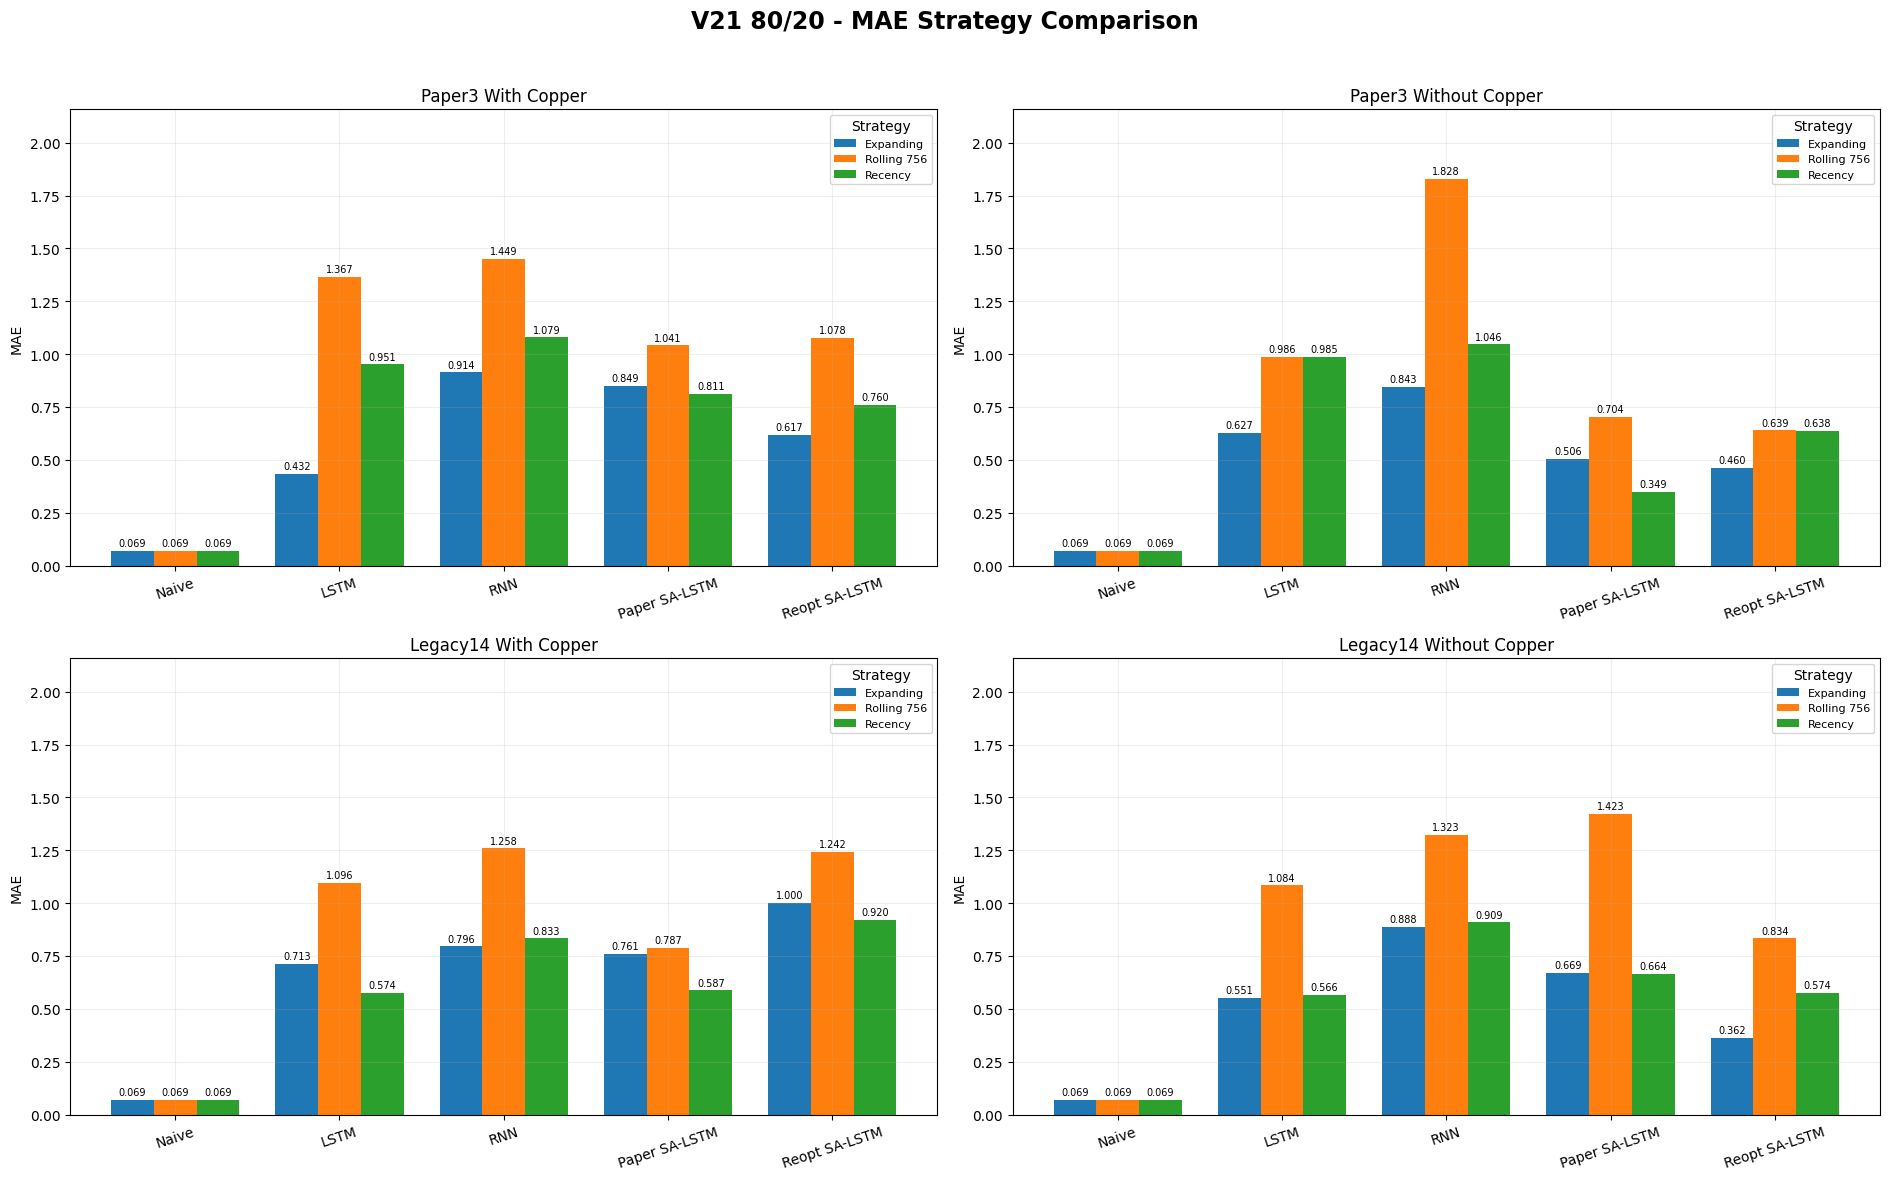

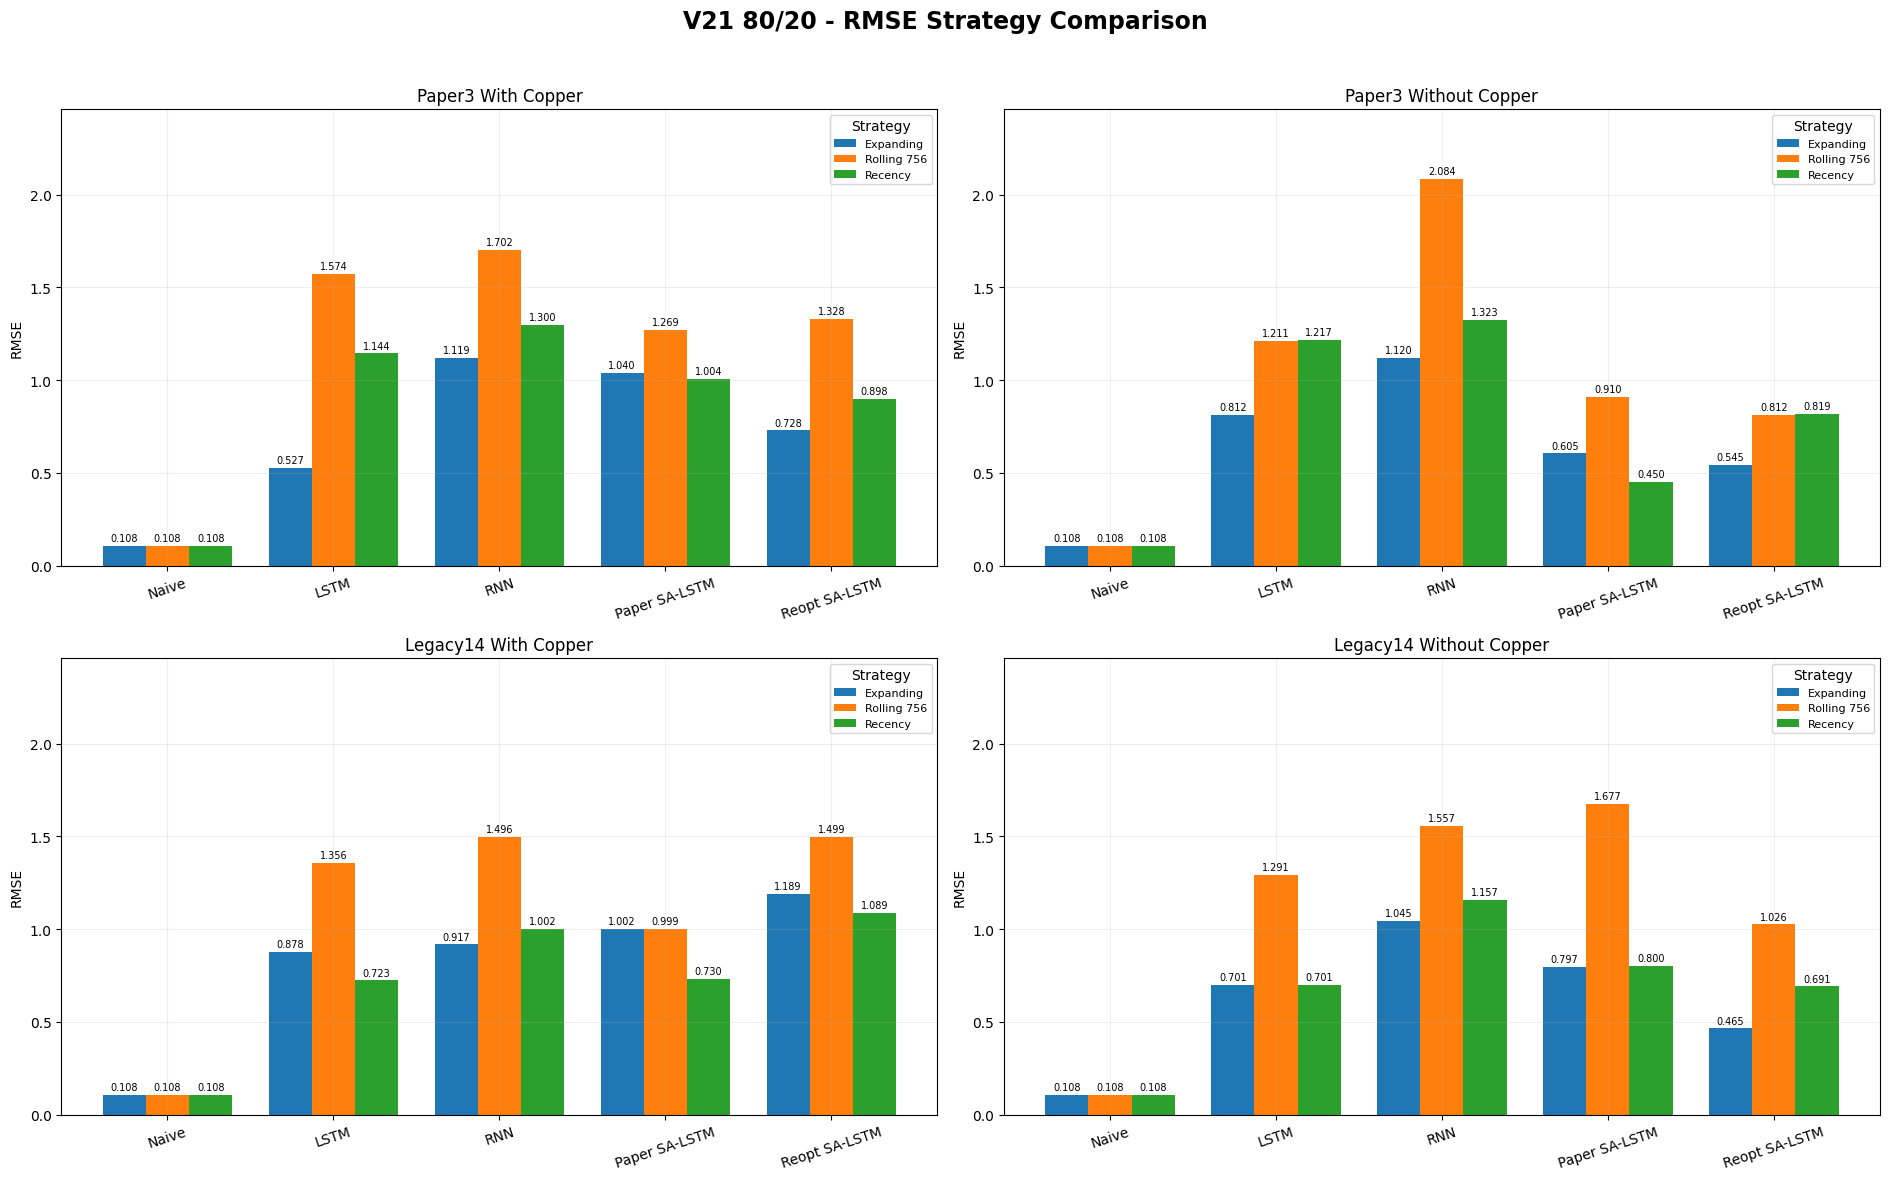

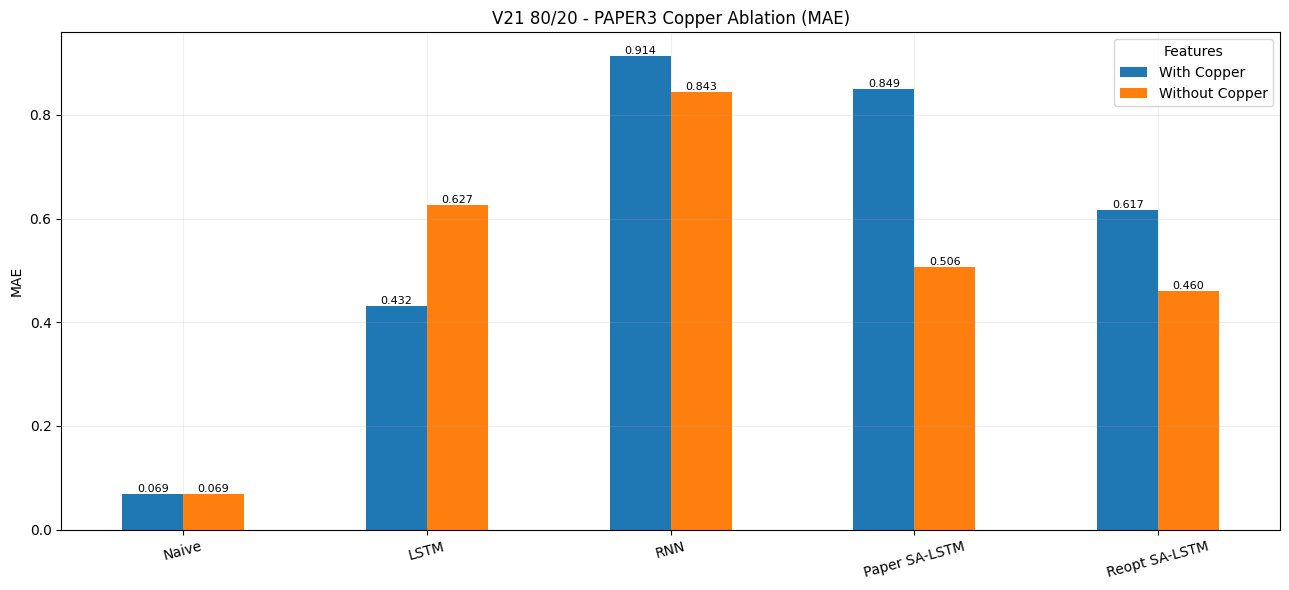

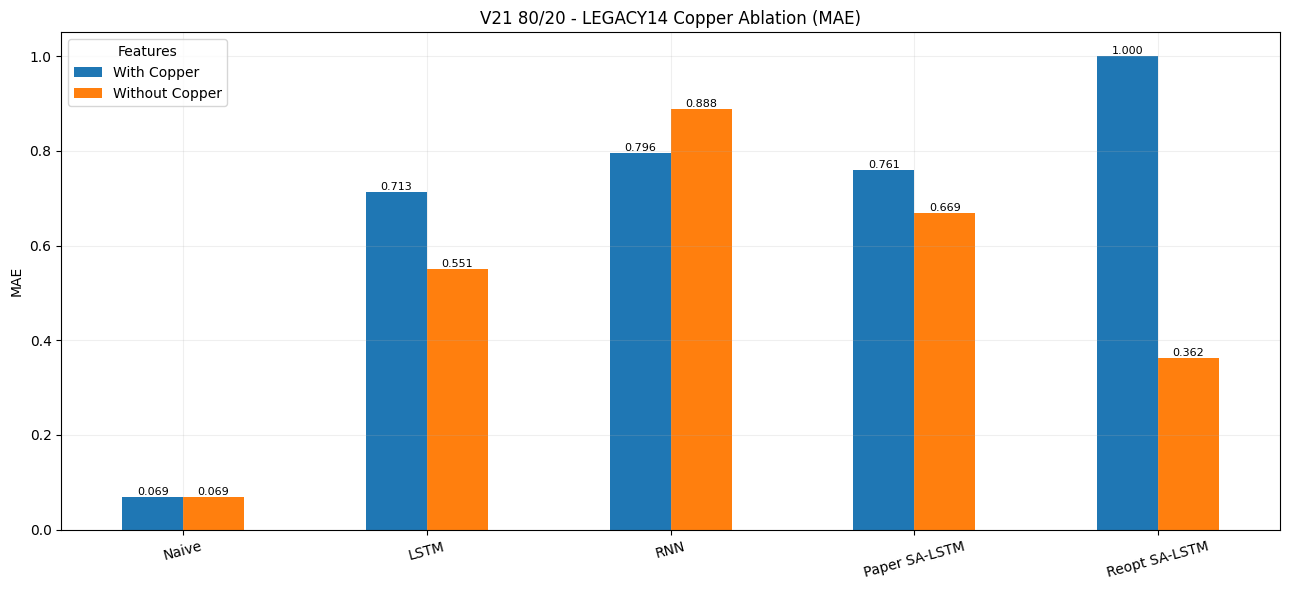

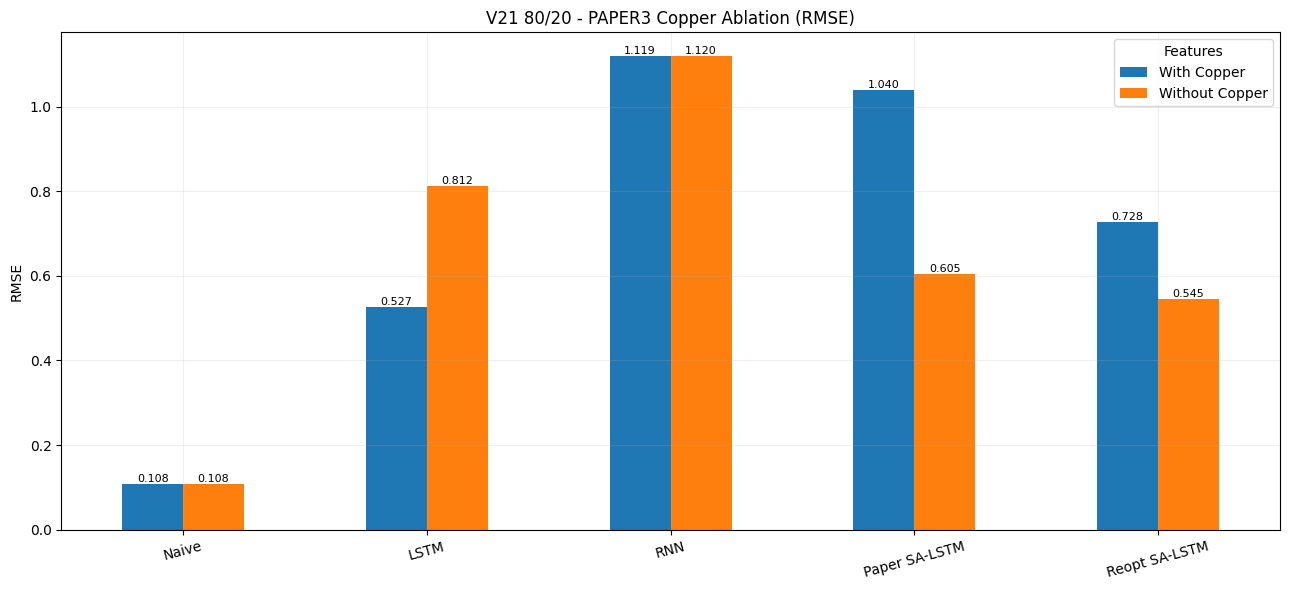

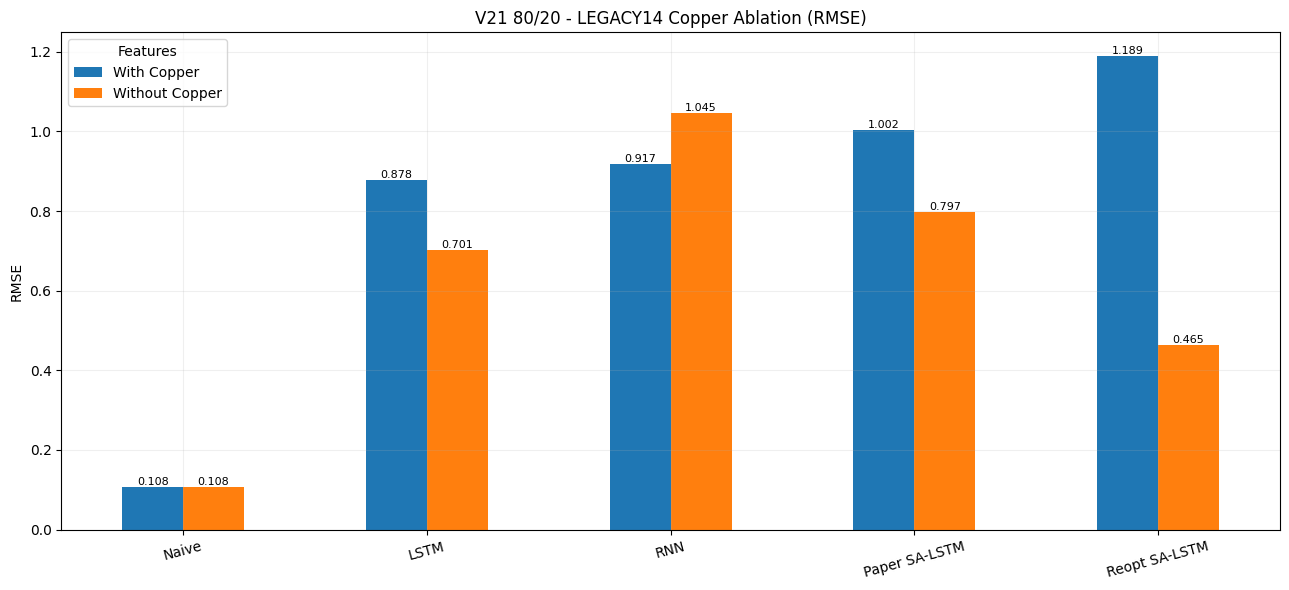

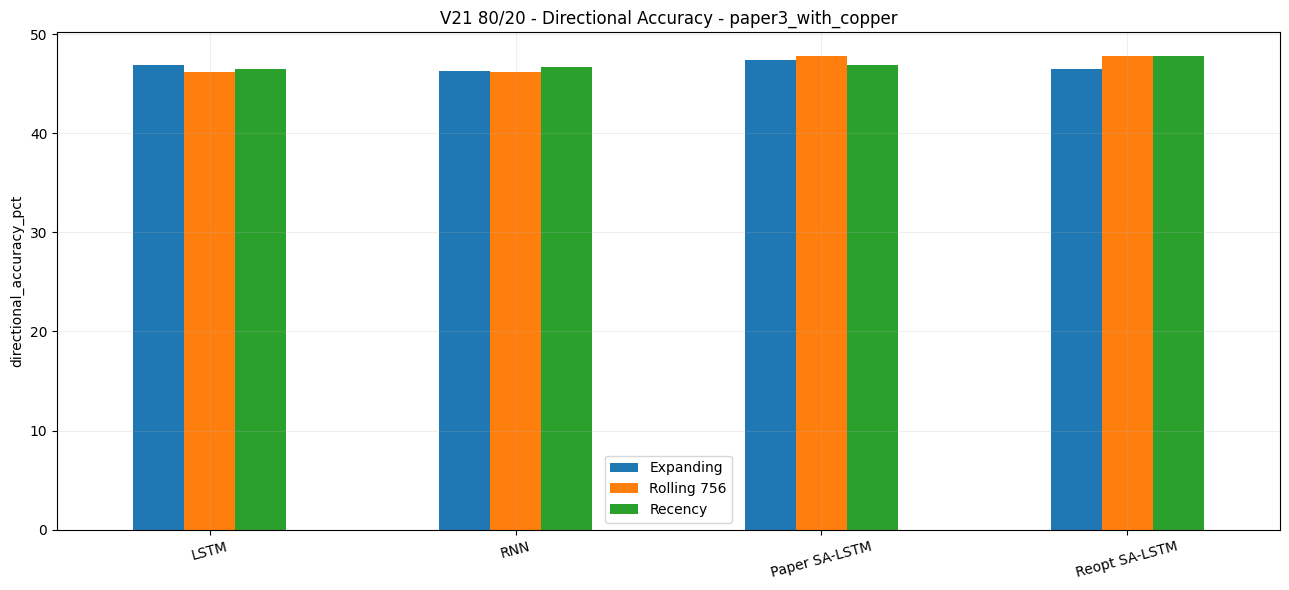

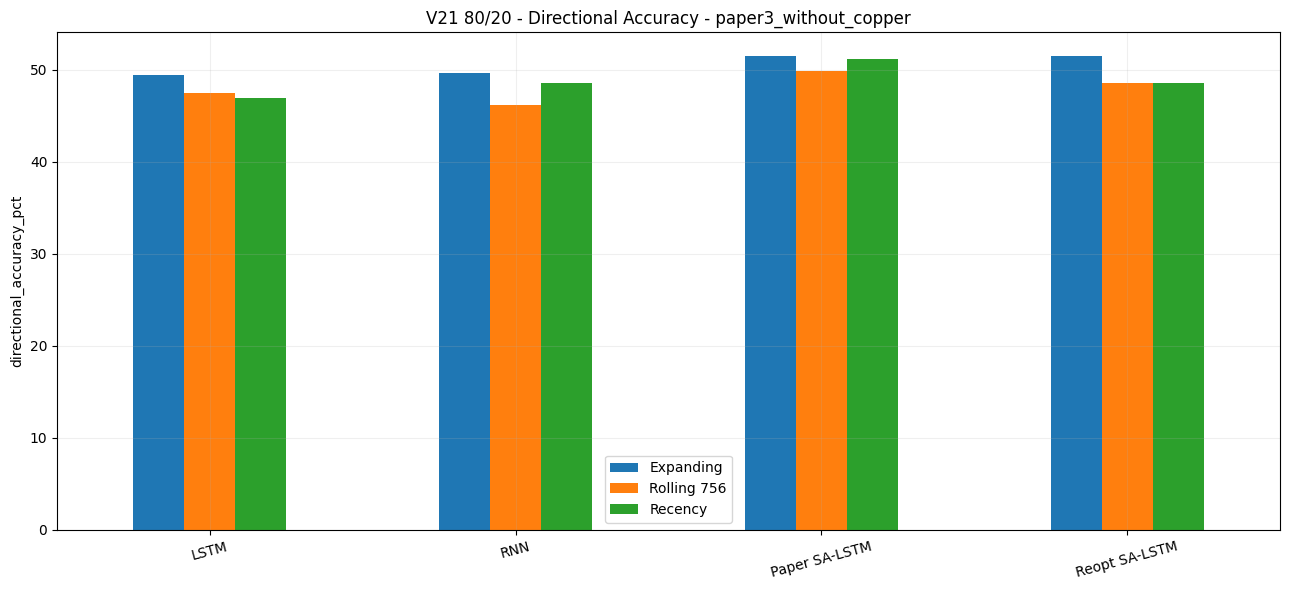

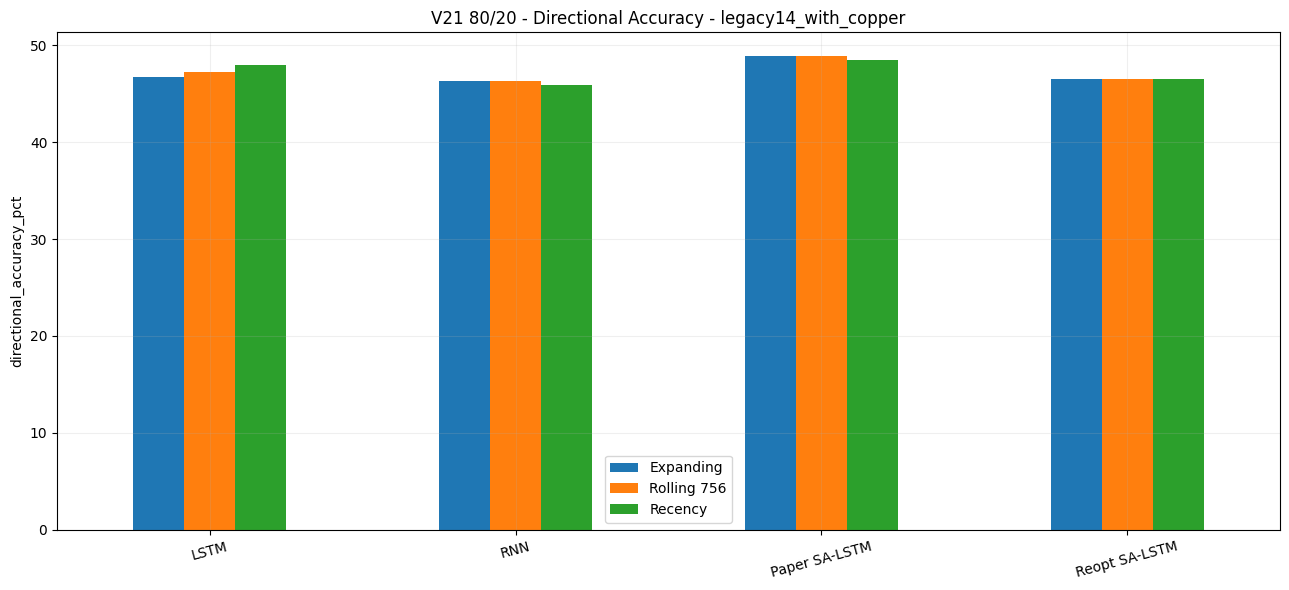

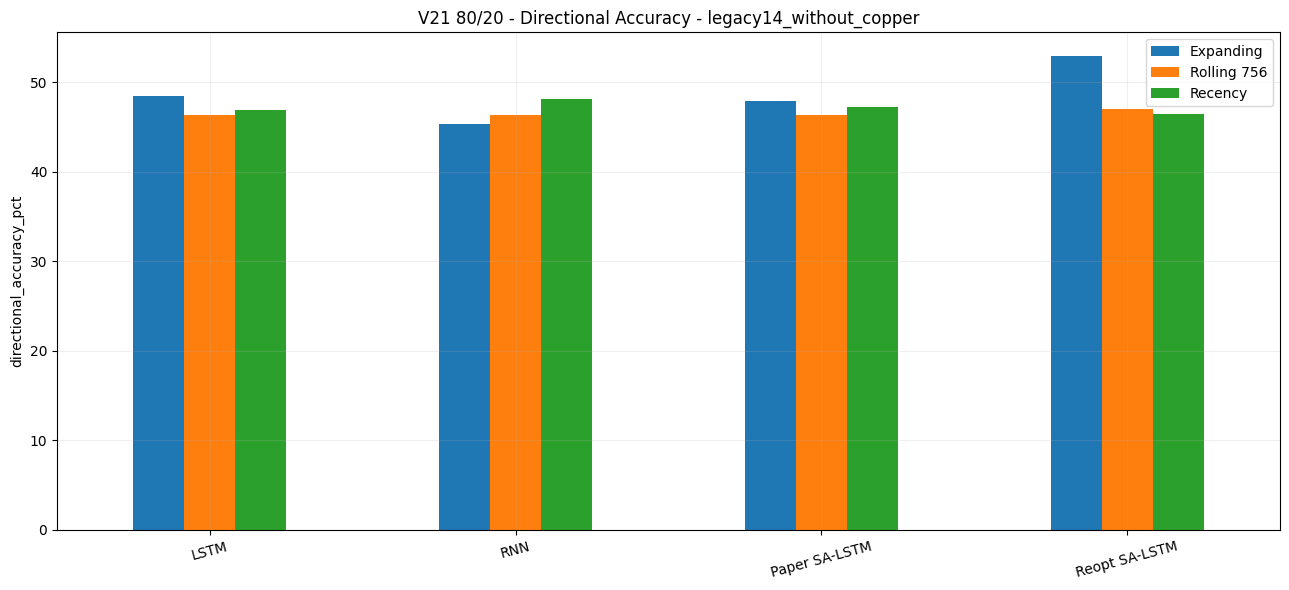

Walk-forward results not found; WF plot skipped.

EXPORT COMPLETE
ZIP: /kaggle/working/copper_sa_lstm_h1_ablation_v21/copper_v21_addon_80_wf_plots.zip
PNG plots: 10
ZIP size: 1.94 MB


/kaggle/working/copper_sa_lstm_h1_ablation_v21/copper_v21_addon_80_wf_plots.zip

In [22]:
# ============================================================
# V21 ADD-ON: PLOTS + EXPORT ZIP
# NO TRAINING / NO RETRAINING
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import json
from pathlib import Path

# ---------- PATHS ----------
ADDON = Path(OUT) / "addon_80_walkforward"
PLOT_DIR = ADDON / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_80 = ADDON / "holdout_80_results.csv"
WF_RESULTS = ADDON / "wf_fold_metrics.csv"
WF_PRED = ADDON / "wf_predictions.csv"

EXPORT_ZIP = Path(OUT) / "copper_v21_addon_80_wf_plots.zip"

assert RESULTS_80.exists(), (
    "Chưa có holdout_80_results.csv. "
    "Hãy chạy xong Part A trước."
)

df = pd.read_csv(RESULTS_80)
df.columns = df.columns.str.strip()

print(f"Loaded {len(df)} holdout evaluations")

FEATURES = [
    "paper3_with_copper",
    "paper3_without_copper",
    "legacy14_with_copper",
    "legacy14_without_copper",
]

MODELS = [
    "naive",
    "baseline_lstm",
    "baseline_rnn",
    "paper_sa_lstm",
    "reopt_sa_lstm",
]

SCHEMES = [
    "expanding",
    "rolling_756",
    "recency_weighted",
]

MODEL_LABELS = {
    "naive": "Naive",
    "baseline_lstm": "LSTM",
    "baseline_rnn": "RNN",
    "paper_sa_lstm": "Paper SA-LSTM",
    "reopt_sa_lstm": "Reopt SA-LSTM",
}

SCHEME_LABELS = {
    "expanding": "Expanding",
    "rolling_756": "Rolling 756",
    "recency_weighted": "Recency",
}

# Check 60 expected combinations
expected = pd.MultiIndex.from_product(
    [FEATURES, SCHEMES, MODELS],
    names=["feature_set", "scheme", "model"]
)

observed = pd.MultiIndex.from_frame(
    df[["feature_set", "scheme", "model"]].drop_duplicates()
)

missing = expected.difference(observed)
print(f"Expected: 60 | Completed: {60 - len(missing)}")

if len(missing):
    print("Missing configurations:")
    print(missing.to_frame(index=False).to_string(index=False))

plt.rcParams.update({
    "figure.figsize": (14, 6),
    "axes.grid": True,
    "grid.alpha": 0.20,
    "font.size": 10,
})

# ============================================================
# 1. STRATEGY COMPARISON: 4 FEATURE SETS x MAE/RMSE
# ============================================================

for metric in ["mae", "rmse"]:
    if metric not in df.columns:
        print(f"Skip metric: {metric}")
        continue

    fig, axes = plt.subplots(2, 2, figsize=(19, 12))
    global_max = df[metric].max() * 1.18

    for ax, fs in zip(axes.flat, FEATURES):
        sub = df[df["feature_set"] == fs]

        pivot = sub.pivot_table(
            index="model",
            columns="scheme",
            values=metric,
            aggfunc="mean"
        )

        pivot = pivot.reindex(
            index=MODELS,
            columns=SCHEMES
        )

        pivot.index = [
            MODEL_LABELS.get(x, x)
            for x in pivot.index
        ]

        pivot.columns = [
            SCHEME_LABELS.get(x, x)
            for x in pivot.columns
        ]

        pivot.plot(
            kind="bar",
            ax=ax,
            width=0.78,
            rot=18,
        )

        ax.set_title(fs.replace("_", " ").title())
        ax.set_ylabel(metric.upper())
        ax.set_xlabel("")
        ax.set_ylim(0, global_max)
        ax.legend(title="Strategy", fontsize=8)

        for container in ax.containers:
            ax.bar_label(
                container,
                fmt="%.3f",
                fontsize=7,
                padding=2
            )

    fig.suptitle(
        f"V21 80/20 - {metric.upper()} Strategy Comparison",
        fontsize=17,
        fontweight="bold"
    )

    fig.tight_layout(rect=[0, 0, 1, 0.96])

    fig.savefig(
        PLOT_DIR / f"80_strategy_{metric}_all_features.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ============================================================
# 2. COPPER HISTORY ABLATION
# ============================================================

for metric in ["mae", "rmse"]:
    if metric not in df.columns:
        continue

    for family in ["paper3", "legacy14"]:
        sub = df[
            df["feature_set"].isin([
                f"{family}_with_copper",
                f"{family}_without_copper",
            ])
            & (df["scheme"] == "expanding")
        ].copy()

        sub["Copper history"] = np.where(
            sub["feature_set"].str.contains("without"),
            "Without Copper",
            "With Copper"
        )

        pivot = sub.pivot_table(
            index="model",
            columns="Copper history",
            values=metric,
            aggfunc="mean"
        ).reindex(MODELS)

        pivot.index = [
            MODEL_LABELS.get(x, x)
            for x in pivot.index
        ]

        ax = pivot.plot(
            kind="bar",
            figsize=(13, 6),
            rot=15
        )

        ax.set_title(
            f"V21 80/20 - {family.upper()} Copper Ablation ({metric.upper()})"
        )
        ax.set_ylabel(metric.upper())
        ax.set_xlabel("")
        ax.legend(title="Features")

        for container in ax.containers:
            ax.bar_label(
                container,
                fmt="%.3f",
                fontsize=8
            )

        plt.tight_layout()

        plt.savefig(
            PLOT_DIR / f"80_ablation_{family}_{metric}.png",
            dpi=250,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# ============================================================
# 3. DIRECTIONAL ACCURACY (IF AVAILABLE)
# ============================================================

da_col = next(
    (c for c in [
        "directional_accuracy",
        "directional_accuracy_pct",
        "direction_accuracy",
        "da"
    ] if c in df.columns),
    None
)

if da_col:
    for fs in FEATURES:
        sub = df[df["feature_set"] == fs]

        pivot = sub.pivot_table(
            index="model",
            columns="scheme",
            values=da_col,
            aggfunc="mean"
        ).reindex(index=MODELS, columns=SCHEMES)

        pivot = pivot.drop(index="naive", errors="ignore")

        if pivot.dropna(how="all").empty:
            continue

        pivot.index = [
            MODEL_LABELS.get(x, x)
            for x in pivot.index
        ]

        pivot.columns = [
            SCHEME_LABELS.get(x, x)
            for x in pivot.columns
        ]

        ax = pivot.plot(
            kind="bar",
            figsize=(13, 6),
            rot=15
        )

        ax.set_title(
            f"V21 80/20 - Directional Accuracy - {fs}"
        )
        ax.set_ylabel(da_col)
        ax.set_xlabel("")

        plt.tight_layout()

        plt.savefig(
            PLOT_DIR / f"80_da_{fs}.png",
            dpi=250,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# ============================================================
# 4. WALK-FORWARD SUMMARY (IF COMPLETED)
# ============================================================

if WF_RESULTS.exists():
    wf = pd.read_csv(WF_RESULTS)
    print(f"Walk-forward fold rows: {len(wf)}")

    required = {"model", "mae", "seed"}

    if required.issubset(wf.columns):
        wf_agg = (
            wf.groupby(["model", "seed"], as_index=False)
              .agg(mean_fold_mae=("mae", "mean"))
        )

        fig, ax = plt.subplots(figsize=(12, 6))

        for model, sub in wf_agg.groupby("model"):
            ax.plot(
                sub["seed"],
                sub["mean_fold_mae"],
                marker="o",
                label=model
            )

        ax.set_title("Walk-forward - Mean Fold MAE by Seed")
        ax.set_xlabel("Random Seed")
        ax.set_ylabel("Mean Fold MAE")
        ax.legend()
        plt.tight_layout()

        plt.savefig(
            PLOT_DIR / "wf_mae_by_seed.png",
            dpi=250,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

        wf_agg.to_csv(
            ADDON / "wf_plot_summary.csv",
            index=False
        )

    else:
        print(
            "WF metrics columns differ; "
            "skipping seed plot."
        )
else:
    print("Walk-forward results not found; WF plot skipped.")

# ============================================================
# 5. EXPORT ALL ADD-ON RESULTS TO SEPARATE ZIP
# ============================================================

manifest = {
    "name": "Copper V21 Add-on 80/20 + Walk-forward",
    "horizon": 1,
    "lookback": 22,
    "holdout_80_rows": int(len(df)),
    "holdout_80_missing_combinations": int(len(missing)),
    "walkforward_metrics_available": WF_RESULTS.exists(),
    "walkforward_predictions_available": WF_PRED.exists(),
    "note": "Plots generated from saved results. No model retraining."
}

(ADDON / "visualization_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

with zipfile.ZipFile(
    EXPORT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:
    for file in ADDON.rglob("*"):
        if file.is_file():
            z.write(
                file,
                arcname=str(file.relative_to(ADDON))
            )

print("\n" + "=" * 60)
print("EXPORT COMPLETE")
print(f"ZIP: {EXPORT_ZIP}")
print(f"PNG plots: {len(list(PLOT_DIR.glob('*.png')))}")
print(f"ZIP size: {EXPORT_ZIP.stat().st_size / 1024**2:.2f} MB")
print("=" * 60)

# Kaggle download
from IPython.display import FileLink, display
display(FileLink(str(EXPORT_ZIP)))